# SIMUTEH P5-P6: Jawaban Pertanyaan Analisis P5.1 sampai P5.5 (SEED = 1007)
**Mata kuliah:** Computer Vision, Teknik Informatika UMMI · **NIM:** 2330521007 · **SEED:** 1007 (4 digit terakhir NIM) · **Bagian 5:** Integrasi modul `bercak.py`



In [1]:
# Sel 1. Menyiapkan folder kerja (struktur sama dengan petunjuk: notebook/, src/, hasil/, data/)
import os, sys
BASE = os.environ.get("SIMUTEH_BASE", "/content/simuteh")
for sub in ["notebook", "src", "hasil", "data"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(f"{BASE}/notebook")      # semua path relatif di bawah ("../src", "../hasil") mengikuti petunjuk
print("Folder kerja:", os.getcwd())

Folder kerja: /content/simuteh/notebook


In [2]:
# Sel 1b. Versi lingkungan (salin ke bagian "Data dan lingkungan" laporan)
import sys, cv2, numpy, pandas, matplotlib, sklearn
print("Python      :", sys.version.split()[0])
print("OpenCV      :", cv2.__version__)
print("NumPy       :", numpy.__version__)
print("pandas      :", pandas.__version__)
print("matplotlib  :", matplotlib.__version__)
print("scikit-learn:", sklearn.__version__)


### Modul-modul pendukung (ditulis ke folder `src/`)
`utils_tepi.py` dan `praproses.py` 

In [3]:
%%writefile ../src/utils_tepi.py
"""utils_tepi.py: fungsi bantu evaluasi deteksi tepi dan morfologi (P5-P6 SIMUTEH)."""
import cv2
import numpy as np


def tepi_acuan(mask):
    """Tepi acuan selebar 1 piksel dari sebuah mask biner (255 = objek)."""
    m = (mask > 0).astype(np.uint8)
    return ((m - cv2.erode(m, np.ones((3, 3), np.uint8))) > 0).astype(np.uint8) * 255


def skor_tepi(prediksi, acuan, toleransi=2):
    """Presisi, recall, dan F1 tepi dengan toleransi jarak (piksel).
    Presisi: porsi piksel tepi prediksi yang berjarak <= toleransi dari tepi acuan.
    Recall : porsi piksel tepi acuan yang berjarak <= toleransi dari tepi prediksi."""
    p = prediksi > 0
    a = acuan > 0
    if p.sum() == 0 or a.sum() == 0:
        return 0.0, 0.0, 0.0
    jarak_ke_a = cv2.distanceTransform((~a).astype(np.uint8), cv2.DIST_L2, 3)
    jarak_ke_p = cv2.distanceTransform((~p).astype(np.uint8), cv2.DIST_L2, 3)
    presisi = float((jarak_ke_a[p] <= toleransi).mean())
    recall = float((jarak_ke_p[a] <= toleransi).mean())
    f1 = 0.0 if presisi + recall == 0 else 2 * presisi * recall / (presisi + recall)
    return round(presisi, 3), round(recall, 3), round(f1, 3)


def iou(a, b):
    """Intersection over Union dua mask biner."""
    a, b = a > 0, b > 0
    gabungan = (a | b).sum()
    return 1.0 if gabungan == 0 else float((a & b).sum() / gabungan)


def mask_daun_awal(img_bgr):
    """Mask daun sementara: ambang Otsu pada kanal saturasi (dibahas tuntas di P7)."""
    s = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 1]
    _, m = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return m


def bercak_awal(img_bgr, mask_daun, kanal=2, k=4.0):
    """Citra biner bercak sementara: piksel daun pada kanal terpilih yang lebih
    terang dari median daun + k x MAD (simpangan median absolut, dikali 1,4826).
    Median dan MAD dipakai karena tidak ikut terseret oleh bercak yang luas.
    Hasilnya sengaja masih kasar: memuat titik derau, potongan tulang daun,
    dan tepi daun yang harus dibersihkan dengan operasi morfologi (P6)."""
    c = img_bgr[:, :, kanal].astype(np.float32)
    m = mask_daun > 0
    med = np.median(c[m])
    mad = 1.4826 * np.median(np.abs(c[m] - med))
    return (((c > med + k * mad) & m) * 255).astype(np.uint8)


Writing ../src/utils_tepi.py


In [4]:
%%writefile ../src/praproses.py
"""praproses.py: rangkaian praproses SIMUTEH (dipakai ulang mulai P5)."""
import json
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,            # sampling: lebar citra kerja (piksel)
    "gamma": "auto",         # angka tetap, atau "auto" (dipilih dari statistik kanal V)
    "clahe_clip": 1.0,       # 0 berarti CLAHE tidak dipakai
    "clahe_tile": 4,
    "clahe_otomatis": True,  # True: CLAHE hanya bila cahaya terdeteksi tidak merata
    "batas_tidak_rata": 0.65,
    "penapis": "median",     # "none", "rerata", "gaussian", "median"
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,          # 0 berarti tanpa penajaman
}


def gamma_otomatis(img_bgr):
    """Memilih gamma dari statistik kanal V (aturan hasil analisis Bagian 3):
    terang (rerata V > 210) -> 1.6; kontras rendah (simp. baku V < 20) -> 1.0;
    gelap (persentil 95 V < 200) -> 0.6; selain itu -> 1.0."""
    v = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 2]
    if v.mean() > 210:
        return 1.6
    if v.std() < 20:
        return 1.0
    if np.percentile(v, 95) < 200:
        return 0.6
    return 1.0


def indeks_tidak_rata(img_bgr):
    """Perkiraan ketidakrataan cahaya: citra dibagi 4 x 4 blok, kecerahan tiap blok
    diwakili persentil 90 kanal V (umumnya latar nampan), lalu dihitung
    (maks - min) / rerata. Nilai besar berarti ada bagian yang jauh lebih teduh."""
    v = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)[:, :, 2].astype(float)
    h, w = v.shape
    blok = [np.percentile(v[i*h//4:(i+1)*h//4, j*w//4:(j+1)*w//4], 90)
            for i in range(4) for j in range(4)]
    return (max(blok) - min(blok)) / np.mean(blok)


def praproses(img_bgr, p=None):
    """Urutan: ubah ukuran -> gamma -> CLAHE kanal V -> redam derau -> tajamkan."""
    p = {**PARAM_BAWAAN, **(p or {})}
    # 1. ubah ukuran, rasio aspek tetap
    h, w = img_bgr.shape[:2]
    img = cv2.resize(img_bgr, (p["lebar"], int(round(h * p["lebar"] / w))),
                     interpolation=cv2.INTER_AREA)
    # 2. koreksi gamma dengan lookup table
    g = gamma_otomatis(img) if p["gamma"] == "auto" else float(p["gamma"])
    if g != 1.0:
        lut = np.array([255 * (i / 255) ** g for i in range(256)])
        img = cv2.LUT(img, lut.clip(0, 255).astype(np.uint8))
    # 3. CLAHE hanya pada kanal V agar warna tidak bergeser
    pakai_clahe = p["clahe_clip"] > 0
    if pakai_clahe and p["clahe_otomatis"]:
        pakai_clahe = indeks_tidak_rata(img) > p["batas_tidak_rata"]
    if pakai_clahe:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
        clahe = cv2.createCLAHE(clipLimit=p["clahe_clip"],
                                tileGridSize=(p["clahe_tile"], p["clahe_tile"]))
        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
    # 4. redam derau
    k = p["kernel"]
    if p["penapis"] == "rerata":
        img = cv2.blur(img, (k, k))
    elif p["penapis"] == "gaussian":
        img = cv2.GaussianBlur(img, (k, k), p["sigma"])
    elif p["penapis"] == "median":
        img = cv2.medianBlur(img, k)
    # 5. tajamkan (unsharp masking) bila diminta
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (5, 5), 1.0)
        img = cv2.addWeighted(img, 1 + p["tajam_k"], blur, -p["tajam_k"], 0)
    return img


def simpan_param(p, path="../hasil/param_praproses.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BAWAAN, **p}, f, indent=2)


Writing ../src/praproses.py


In [5]:
%%writefile ../src/utils_cv.py
"""utils_cv.py: fungsi bantu baca dan tampil citra (dipakai notebook P5-P6)."""
import cv2
import numpy as np
import matplotlib.pyplot as plt


def baca(path):
    """Membaca citra berwarna (BGR). Galat bila berkas tidak ditemukan."""
    img = cv2.imread(path, cv2.IMREAD_COLOR)
    if img is None:
        raise FileNotFoundError(path)
    return img


def tampil(daftar, judul=None, baris=1, ukuran=(14, 4)):
    """Menampilkan beberapa citra dalam satu panel (BGR -> RGB, biner -> abu-abu)."""
    n = len(daftar)
    kolom = int(np.ceil(n / baris))
    plt.figure(figsize=ukuran)
    for i, im in enumerate(daftar):
        plt.subplot(baris, kolom, i + 1)
        if im.ndim == 3:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        else:
            plt.imshow(im, cmap="gray", vmin=0, vmax=255)
        if judul is not None:
            plt.title(judul[i], fontsize=8)
        plt.axis("off")
    plt.tight_layout()


Writing ../src/utils_cv.py


In [6]:
%%writefile ../src/data_sintetis.py
"""data_sintetis.py: pembangkit dataset sintetis daun teh SIMUTEH (60 citra, 640 x 480)."""
import os
import cv2
import numpy as np
import pandas as pd

KONDISI = ["normal", "terang", "gelap", "kontras_rendah", "tidak_merata"]
H, W = 480, 640


def _derau_halus(rng, skala, amp):
    kecil = rng.normal(0, 1, (H // skala + 2, W // skala + 2)).astype(np.float32)
    return amp * cv2.resize(kecil, (W, H), interpolation=cv2.INTER_CUBIC)


def _bentuk_bercak(rng, mask, cx, cy, r, bentuk):
    """Menggambar satu bercak pada mask. bentuk: bulat | tak_beraturan."""
    if bentuk == "bulat":
        cv2.circle(mask, (cx, cy), r, 255, -1)
        return
    if rng.random() < 0.5:   # memanjang
        rasio = rng.uniform(2.0, 3.2)
        a, b = int(r * np.sqrt(rasio)), max(2, int(r / np.sqrt(rasio)))
        cv2.ellipse(mask, (cx, cy), (a, b), rng.uniform(0, 180), 0, 360, 255, -1)
    else:                     # gumpalan bergerigi
        n = 18
        sudut = np.linspace(0, 2 * np.pi, n, endpoint=False)
        rad = r * (1 + 0.45 * rng.uniform(-1, 1, n))
        titik = np.stack([cx + rad * np.cos(sudut), cy + rad * np.sin(sudut)], 1).astype(np.int32)
        cv2.fillPoly(mask, [titik], 255)


def buat_citra(rng, kelas, kondisi, bentuk="bulat"):
    """Mengembalikan citra BGR, mask_daun, mask_bercak (semuanya uint8)."""
    # ---- latar nampan (pucat) dan daun (hijau pekat) ----
    nampan = np.array([rng.integers(190, 215), rng.integers(205, 225), rng.integers(212, 232)], np.float32)
    img = np.ones((H, W, 3), np.float32) * nampan + _derau_halus(rng, 40, 4)[:, :, None]
    cx, cy = 320 + rng.integers(-20, 21), 240 + rng.integers(-15, 16)
    a, b = int(rng.integers(205, 236)), int(rng.integers(105, 126))
    sudut = float(rng.uniform(-15, 15))
    m_daun = np.zeros((H, W), np.uint8)
    cv2.ellipse(m_daun, (cx, cy), (a, b), sudut, 0, 360, 255, -1)
    daun = np.array([rng.integers(35, 55), rng.integers(115, 140), rng.integers(30, 50)], np.float32)
    tekstur = _derau_halus(rng, 6, 3.0)[:, :, None] + _derau_halus(rng, 60, 5.0)[:, :, None]
    img[m_daun > 0] = (daun + tekstur)[m_daun > 0]
    # tulang daun (garis lebih terang sepanjang sumbu panjang)
    t = np.deg2rad(sudut)
    p1 = (int(cx - (a - 6) * np.cos(t)), int(cy - (a - 6) * np.sin(t)))
    p2 = (int(cx + (a - 6) * np.cos(t)), int(cy + (a - 6) * np.sin(t)))
    tulang = np.zeros((H, W), np.uint8)
    cv2.line(tulang, p1, p2, 255, 4)
    tulang = cv2.bitwise_and(tulang, m_daun)
    img[tulang > 0] = img[tulang > 0] * 0.4 + np.array([105, 185, 110], np.float32) * 0.6
    # ---- bercak ----
    m_bercak = np.zeros((H, W), np.uint8)
    luas_daun = float((m_daun > 0).sum())
    if kelas != "sehat":
        for _ in range(200):
            if kelas == "ringan":
                n, rentang, tmin, tmaks = int(rng.integers(2, 5)), (3, 8), 0.15, 1.8
            else:
                n, rentang, tmin, tmaks = int(rng.integers(4, 9)), (9, 24), 2.3, 9.0
            mk = np.zeros((H, W), np.uint8)
            pusat, ok = [], True
            for _ in range(n):
                for _ in range(100):
                    r = int(rng.integers(rentang[0], rentang[1] + 1))
                    u, v = rng.uniform(-1, 1, 2)
                    if u * u + v * v > 0.55:
                        continue
                    px, py = u * (a - 2.2 * r - 8), v * (b - 2.2 * r - 8)
                    x = int(cx + px * np.cos(t) - py * np.sin(t))
                    y = int(cy + px * np.sin(t) + py * np.cos(t))
                    if all((x - x2) ** 2 + (y - y2) ** 2 > (1.7 * (r + r2) + 8) ** 2 for x2, y2, r2 in pusat):
                        pusat.append((x, y, r)); break
                else:
                    ok = False
            if not ok:
                continue
            for x, y, r in pusat:
                _bentuk_bercak(rng, mk, x, y, r, bentuk)
            mk = cv2.bitwise_and(mk, m_daun)
            persen = 100 * (mk > 0).sum() / luas_daun
            if tmin <= persen <= tmaks:
                m_bercak = mk; break
        # warna bercak: cincin cokelat di tepi, inti kuning-oranye
        inti = cv2.erode(m_bercak, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)))
        inti = cv2.erode(m_bercak, np.ones((3, 3), np.uint8), iterations=2)
        cincin = (m_bercak > 0) & (inti == 0)
        img[cincin] = np.array([40, 105, 170], np.float32) + rng.normal(0, 4, 3)
        img[inti > 0] = np.array([70, 190, 235], np.float32) + rng.normal(0, 4, 3)
    # tepi daun sedikit memudar (antialiasing alami)
    # ---- kondisi cahaya ----
    if kondisi == "terang":
        img = img * 1.12 + 28
    elif kondisi == "gelap":
        img = img * 0.55
    elif kondisi == "kontras_rendah":
        img = 0.45 * img + 0.55 * img.mean()
    elif kondisi == "tidak_merata":
        gx = np.linspace(1.0, 0.42, W, dtype=np.float32)[None, :]
        gy = np.linspace(1.0, 0.8, H, dtype=np.float32)[:, None]
        img = img * (gx * gy)[:, :, None]
    # derau sensor + bintik terang kecil (sebagai derau)
    img = img + rng.normal(0, 3.0, img.shape).astype(np.float32)
    bintik = rng.random((H, W)) < 0.0006
    img[bintik & (m_daun > 0)] = 200
    img = cv2.GaussianBlur(img, (3, 3), 0.6)
    return np.clip(img, 0, 255).astype(np.uint8), m_daun, m_bercak


def buat_dataset(seed, akar="../data/sintetis", bentuk="bulat", per_kelas=20, mulai=1):
    """Membuat citra/, mask_daun/, mask_bercak/, dan label.csv. 1-20 sehat, 21-40 ringan, 41-60 berat."""
    rng = np.random.default_rng(seed)
    for sub in ["citra", "mask_daun", "mask_bercak"]:
        os.makedirs(f"{akar}/{sub}", exist_ok=True)
    baris, nomor = [], mulai
    for kelas in ["sehat", "ringan", "berat"]:
        for i in range(per_kelas):
            kond = KONDISI[i % len(KONDISI)]
            img, md, mb = buat_citra(rng, kelas, kond, bentuk)
            nama = f"teh_{nomor:03d}.png"
            cv2.imwrite(f"{akar}/citra/{nama}", img)
            cv2.imwrite(f"{akar}/mask_daun/{nama}", md)
            cv2.imwrite(f"{akar}/mask_bercak/{nama}", mb)
            persen = round(100 * (mb > 0).sum() / (md > 0).sum(), 3)
            baris.append([nama, kelas, kond, persen])
            nomor += 1
    lab = pd.DataFrame(baris, columns=["nama_file", "kelas", "kondisi_cahaya", "persen_bercak"])
    lab.to_csv(f"{akar}/label.csv", index=False)
    return lab


Writing ../src/data_sintetis.py


In [7]:
%%writefile ../src/bercak.py
"""bercak.py: analisis bercak SIMUTEH (dipakai ulang mulai P7)."""
import json
import cv2
import numpy as np
from utils_tepi import mask_daun_awal, bercak_awal

PARAM_BERCAK = {
    "kanal": 2,            # kanal terpilih (2 = R)
    "k": 4.0,              # ambang median + k x MAD
    "se_bentuk": "elips",  # "elips", "persegi", "silang"
    "se_open": 5,          # ukuran SE opening (0 = tidak dipakai)
    "se_close": 5,         # ukuran SE closing (0 = tidak dipakai)
    "luas_min": 20,        # piksel
    "bulat_min": 0.5,
    "rasio_maks": 1.8,
    "batas_ringan": 0.1,   # persen bercak minimum kelas Ringan
    "batas_berat": 2.0,    # persen bercak minimum kelas Berat
    "mm_per_px": 0.4375,
}

_BENTUK = {"elips": cv2.MORPH_ELLIPSE, "persegi": cv2.MORPH_RECT, "silang": cv2.MORPH_CROSS}


def _se(p, uk):
    return cv2.getStructuringElement(_BENTUK[p["se_bentuk"]], (uk, uk))


def bersihkan(biner, p):
    """Opening membuang titik derau dan potongan tipis; closing menutup celah."""
    # TODO 1 (selesai): opening bila se_open > 0
    if p["se_open"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_OPEN, _se(p, p["se_open"]))
    # TODO 2 (selesai): closing bila se_close > 0
    if p["se_close"] > 0:
        biner = cv2.morphologyEx(biner, cv2.MORPH_CLOSE, _se(p, p["se_close"]))
    return biner


def ukur_dan_saring(biner, p):
    """Mengembalikan mask bercak tersaring dan daftar ukuran setiap bercak."""
    # TODO 3 (selesai): label komponen terhubung, konektivitas 8
    n, lbl, st, cen = cv2.connectedComponentsWithStats((biner > 0).astype(np.uint8), connectivity=8)
    keluar, daftar = np.zeros_like(biner), []
    for i in range(1, n):
        # TODO 4 (selesai): luas, keliling, kebulatan, rasio aspek
        komp = (lbl == i).astype(np.uint8)
        kontur, _ = cv2.findContours(komp, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        luas = int(st[i, cv2.CC_STAT_AREA])
        keliling = cv2.arcLength(kontur[0], True)
        kebulatan = 0.0 if keliling == 0 else 4 * np.pi * luas / keliling ** 2
        w, h = cv2.minAreaRect(kontur[0])[1]
        rasio = max(w, h) / max(min(w, h), 1)
        # TODO 5 (selesai): simpan hanya komponen yang lolos tiga aturan
        if luas >= p["luas_min"] and kebulatan >= p["bulat_min"] and rasio <= p["rasio_maks"]:
            keluar[lbl == i] = 255
            daftar.append({"luas_px": luas,
                           "luas_mm2": round(luas * p["mm_per_px"] ** 2, 2),
                           "keliling_px": round(float(keliling), 1),
                           "kebulatan": round(float(kebulatan), 2),
                           "rasio_aspek": round(float(rasio), 2),
                           "cx": int(cen[i][0]), "cy": int(cen[i][1])})
    return keluar, daftar


def analisis_daun(img_praproses, p=None):
    """Masukan: citra BGR hasil praproses. Keluaran: kamus hasil analisis."""
    p = {**PARAM_BERCAK, **(p or {})}
    m_daun = mask_daun_awal(img_praproses)
    biner = bercak_awal(img_praproses, m_daun, kanal=p["kanal"], k=p["k"])
    m_bercak, daftar = ukur_dan_saring(bersihkan(biner, p), p)
    # TODO 6 (selesai): persen bercak = luas bercak / luas daun x 100
    luas_daun = int((m_daun > 0).sum())
    persen = 100.0 * int((m_bercak > 0).sum()) / luas_daun if luas_daun > 0 else 0.0
    # TODO 7 (selesai): kelas dari batas_ringan dan batas_berat
    if persen >= p["batas_berat"]:
        kelas = "Bercak Berat"
    elif persen >= p["batas_ringan"]:
        kelas = "Bercak Ringan"
    else:
        kelas = "Sehat"
    return {"mask_daun": m_daun, "mask_bercak": m_bercak, "jumlah_bercak": len(daftar),
            "persen_bercak": round(float(persen), 3), "kelas": kelas, "bercak": daftar}


def simpan_param(p, path="../hasil/param_bercak.json"):
    with open(path, "w") as f:
        json.dump({**PARAM_BERCAK, **p}, f, indent=2)


Writing ../src/bercak.py


In [8]:
# Sel 2. Membangkitkan dataset sintetis (foto + mask acuan + label.csv)
sys.path.append("../src")
import json, cv2, numpy as np, pandas as pd, matplotlib.pyplot as plt
from utils_cv import baca, tampil
from praproses import praproses, PARAM_BAWAAN
from utils_tepi import tepi_acuan, skor_tepi, iou, mask_daun_awal, bercak_awal
from data_sintetis import buat_dataset
import bercak
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

SEED = 1007                      # 4 digit terakhir NIM 2330521007 (dataset kedua pada Sel 12 memakai SEED + 1)
label = buat_dataset(SEED, "../data/sintetis")
print("Jumlah citra:", len(label))
print(label.groupby(["kelas", "kondisi_cahaya"]).size().unstack())
print(label.groupby("kelas").persen_bercak.agg(["min", "mean", "max"]).round(3))

Jumlah citra: 60
kondisi_cahaya  gelap  kontras_rendah  normal  terang  tidak_merata
kelas                                                              
berat               4               4       4       4             4
ringan              4               4       4       4             4
sehat               4               4       4       4             4
          min   mean    max
kelas                      
berat   2.448  4.383  5.749
ringan  0.154  0.395  0.797
sehat   0.000  0.000  0.000


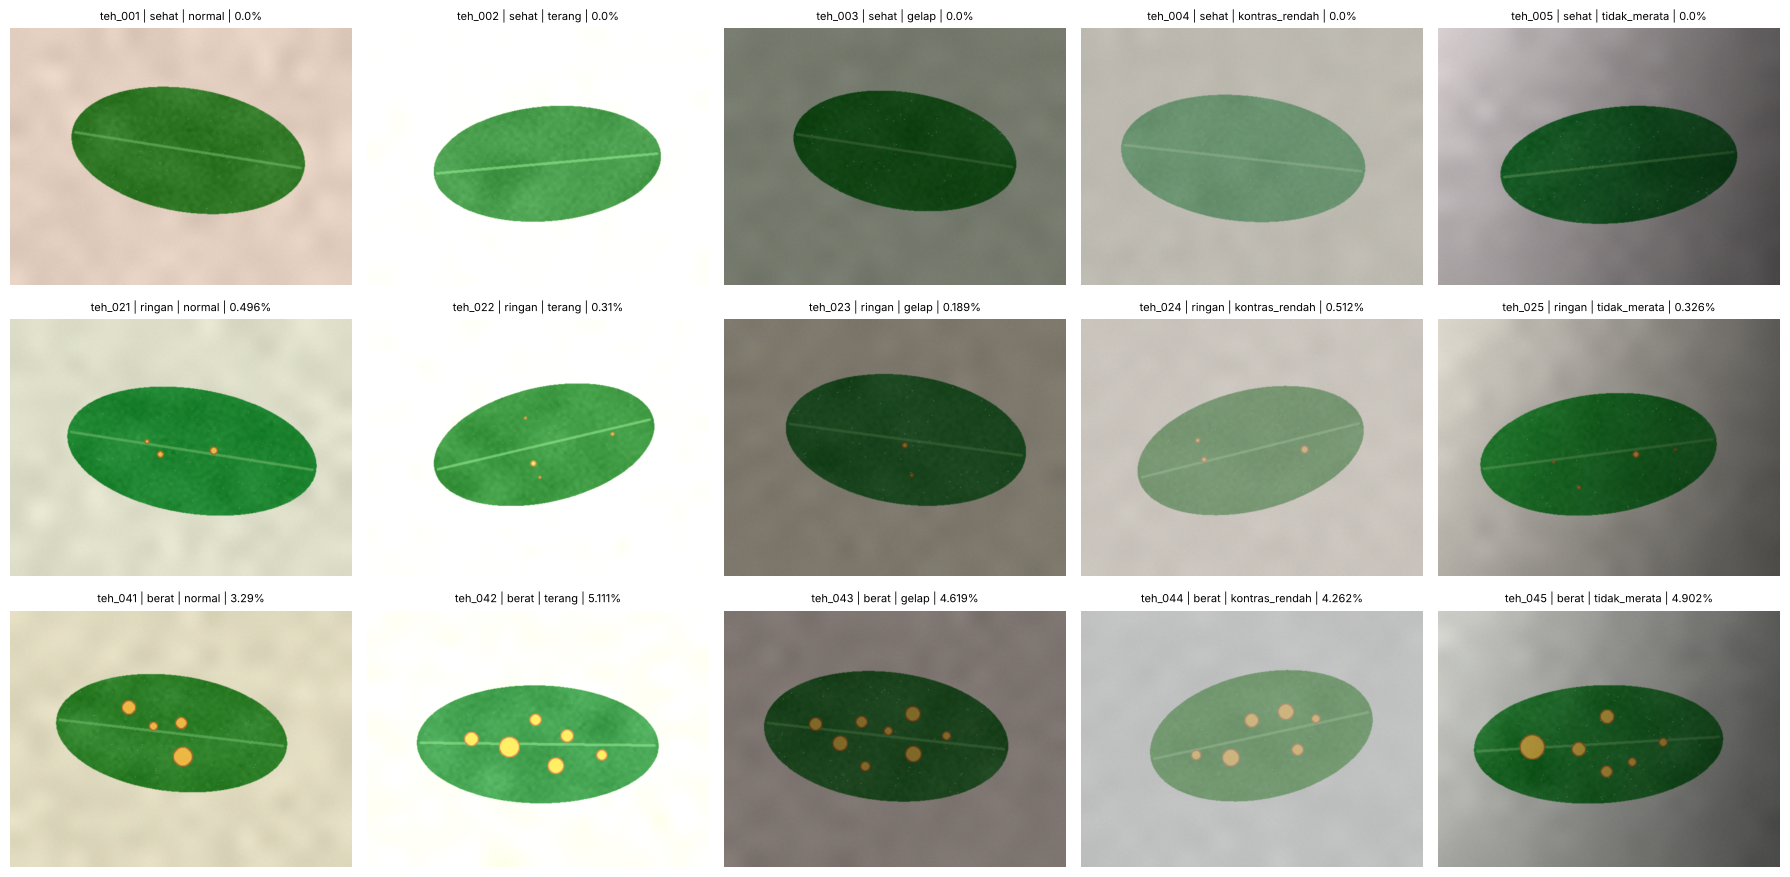

In [9]:
# Sel 3. Contoh foto dataset: baris = kelas, kolom = kondisi cahaya
contoh = ["teh_001", "teh_002", "teh_003", "teh_004", "teh_005",     # sehat
          "teh_021", "teh_022", "teh_023", "teh_024", "teh_025",     # ringan
          "teh_041", "teh_042", "teh_043", "teh_044", "teh_045"]     # berat
ims, jd = [], []
for nm in contoh:
    d = label[label.nama_file == nm + ".png"].iloc[0]
    ims.append(baca(f"../data/sintetis/citra/{nm}.png"))
    jd.append(f"{nm} | {d.kelas} | {d.kondisi_cahaya} | {d.persen_bercak}%")
tampil(ims, jd, baris=3, ukuran=(18, 9))
plt.savefig("../hasil/p5_dataset_contoh.png", dpi=110); plt.show()

In [10]:
# Sel 4. Persiapan (Kode 1.1): parameter praproses, fungsi muat, dan cache praproses 60 citra
json.dump(PARAM_BAWAAN, open("../hasil/param_praproses.json", "w"), indent=2)
PARAM = json.load(open("../hasil/param_praproses.json"))

def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md_ = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb_ = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md_, mb_

CACHE = {}
for _, d in label.iterrows():
    img, md_, mb_ = muat(d.nama_file)
    CACHE[d.nama_file] = (praproses(img, PARAM), md_, mb_)
print("Cache praproses siap:", len(CACHE), "citra")

def jumlah_komponen(m, konek=8):
    return cv2.connectedComponents((m > 0).astype(np.uint8), connectivity=konek)[0] - 1

Cache praproses siap: 60 citra


## Langkah 5.1 sampai 5.2: modul `bercak.py` dan evaluasi pada 60 citra
Ketujuh TODO pada `bercak.py` sudah dilengkapi (lihat sel penulisan modul di atas). Berikut evaluasi sesuai Kode 5.2.

Galat absolut rerata persen bercak: 0.658
Korelasi persen prediksi vs acuan : 0.854
Akurasi kelas : 0.833 (50 dari 60)

prediksi       Bercak Berat  Bercak Ringan  Sehat
acuan                                            
Bercak Berat             13              7      0
Bercak Ringan             0             17      3
Sehat                     0              0     20

Akurasi per kondisi cahaya:
kondisi
gelap             0.83
kontras_rendah    0.92
normal            0.92
terang            0.75
tidak_merata      0.75
Name: benar, dtype: float64

Rerata persen per kelas (acuan vs prediksi):
        persen_acuan  persen_prediksi
kelas                                
berat          4.383            2.539
ringan         0.395            0.312
sehat          0.000            0.002


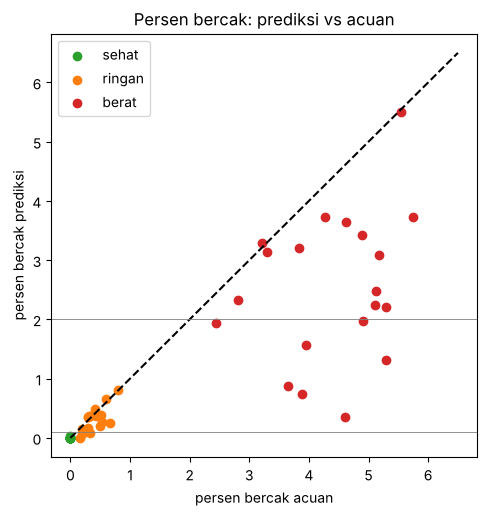

In [11]:
# Sel 5. Evaluasi menyeluruh modul bercak.py (Kode 5.2)
import importlib
importlib.reload(bercak)
PB = {}                                     # kosong = parameter bawaan
bercak.simpan_param(PB)
HASIL = {}                                  # simpan keluaran tiap citra untuk analisis lanjutan
baris = []
for _, d in label.iterrows():
    pra_, md_, mb_ = CACHE[d.nama_file]
    h = bercak.analisis_daun(pra_, PB)
    HASIL[d.nama_file] = h
    baris.append([d.nama_file, d.kelas, d.kondisi_cahaya, d.persen_bercak, h["persen_bercak"],
                  jumlah_komponen(mb_), h["jumlah_bercak"], h["kelas"]])
ev = pd.DataFrame(baris, columns=["nama", "kelas", "kondisi", "persen_acuan", "persen_prediksi",
                                  "jumlah_acuan", "jumlah_prediksi", "kelas_prediksi"])
ev["kelas_acuan"] = ev.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})
ev["benar"] = ev.kelas_prediksi == ev.kelas_acuan
ev.to_csv("../hasil/p6_evaluasi_bercak.csv", index=False)
print("Galat absolut rerata persen bercak:", (ev.persen_prediksi - ev.persen_acuan).abs().mean().round(3))
print("Korelasi persen prediksi vs acuan :", ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1].round(3))
print("Akurasi kelas :", ev.benar.mean().round(3), f"({ev.benar.sum()} dari {len(ev)})")
print()
print(pd.crosstab(ev.kelas_acuan, ev.kelas_prediksi, rownames=["acuan"], colnames=["prediksi"]))
print()
print("Akurasi per kondisi cahaya:"); print(ev.groupby("kondisi").benar.mean().round(2))
print()
print("Rerata persen per kelas (acuan vs prediksi):")
print(ev.groupby("kelas")[["persen_acuan", "persen_prediksi"]].mean().round(3))
plt.figure(figsize=(5.5, 5.5))
for kls, wr in [("sehat", "tab:green"), ("ringan", "tab:orange"), ("berat", "tab:red")]:
    s = ev[ev.kelas == kls]; plt.scatter(s.persen_acuan, s.persen_prediksi, c=wr, label=kls)
plt.plot([0, 6.5], [0, 6.5], "k--"); plt.axhline(0.1, c="gray", lw=.6); plt.axhline(2.0, c="gray", lw=.6)
plt.xlabel("persen bercak acuan"); plt.ylabel("persen bercak prediksi"); plt.legend(); plt.title("Persen bercak: prediksi vs acuan")
plt.savefig("../hasil/p5_scatter_persen.png", dpi=110, bbox_inches="tight"); plt.show()

In [12]:
# Sel 6. Tabel 12: ringkasan evaluasi
akur_kond = ev.groupby("kondisi").benar.mean()
tabel12 = pd.DataFrame({
    "Ukuran": ["Galat absolut rerata persen bercak", "Korelasi persen prediksi dan acuan", "Akurasi kelas",
               "Jumlah daun sehat yang dinilai berbercak", "Jumlah daun berbercak yang dinilai sehat",
               "Kondisi cahaya dengan akurasi terendah"],
    "Nilai": [round((ev.persen_prediksi - ev.persen_acuan).abs().mean(), 3),
              round(ev[["persen_prediksi", "persen_acuan"]].corr().iloc[0, 1], 3),
              round(ev.benar.mean(), 3),
              int(((ev.kelas == "sehat") & (ev.kelas_prediksi != "Sehat")).sum()),
              int(((ev.kelas != "sehat") & (ev.kelas_prediksi == "Sehat")).sum()),
              " dan ".join(akur_kond[akur_kond == akur_kond.min()].index) + f" ({akur_kond.min():.2f})"]})
tabel12.to_csv("../hasil/p6_tabel12.csv", index=False)
tabel12

,Ukuran,Nilai
0,Galat absolut rerata persen bercak,0.658
1,Korelasi persen prediksi dan acuan,0.854
2,Akurasi kelas,0.833
3,Jumlah daun sehat yang dinilai berbercak,0
4,Jumlah daun berbercak yang dinilai sehat,3
5,Kondisi cahaya dengan akurasi terendah,terang dan tidak_merata (0.75)


## Langkah 5.3: analisis kesalahan (citra yang salah kelas)
Untuk tiap citra salah kelas ditampilkan citra praproses, mask bercak hasil, dan mask acuan, disertai diagnosis angka: berapa bercak acuan yang terdeteksi, berapa piksel acuan tertutup, dan berapa komponen palsu.

Jumlah citra salah kelas: 10
       nama        kondisi   kelas_acuan kelas_prediksi  persen_acuan  persen_prediksi  bercak_acuan  terdeteksi  komponen_palsu  piksel_acuan_tertutup_%  IoU_daun
teh_023.png          gelap Bercak Ringan          Sehat         0.189            0.069             2           1               0                     30.2     0.997
teh_025.png   tidak_merata Bercak Ringan          Sehat         0.326            0.074             4           1               0                     19.1     1.000
teh_037.png         terang Bercak Ringan          Sehat         0.154            0.000             2           0               0                      0.0     1.000
teh_045.png   tidak_merata  Bercak Berat  Bercak Ringan         4.902            1.972             6           4               0                     39.0     1.000
teh_046.png         normal  Bercak Berat  Bercak Ringan         3.645            0.877             5           2               0                     22

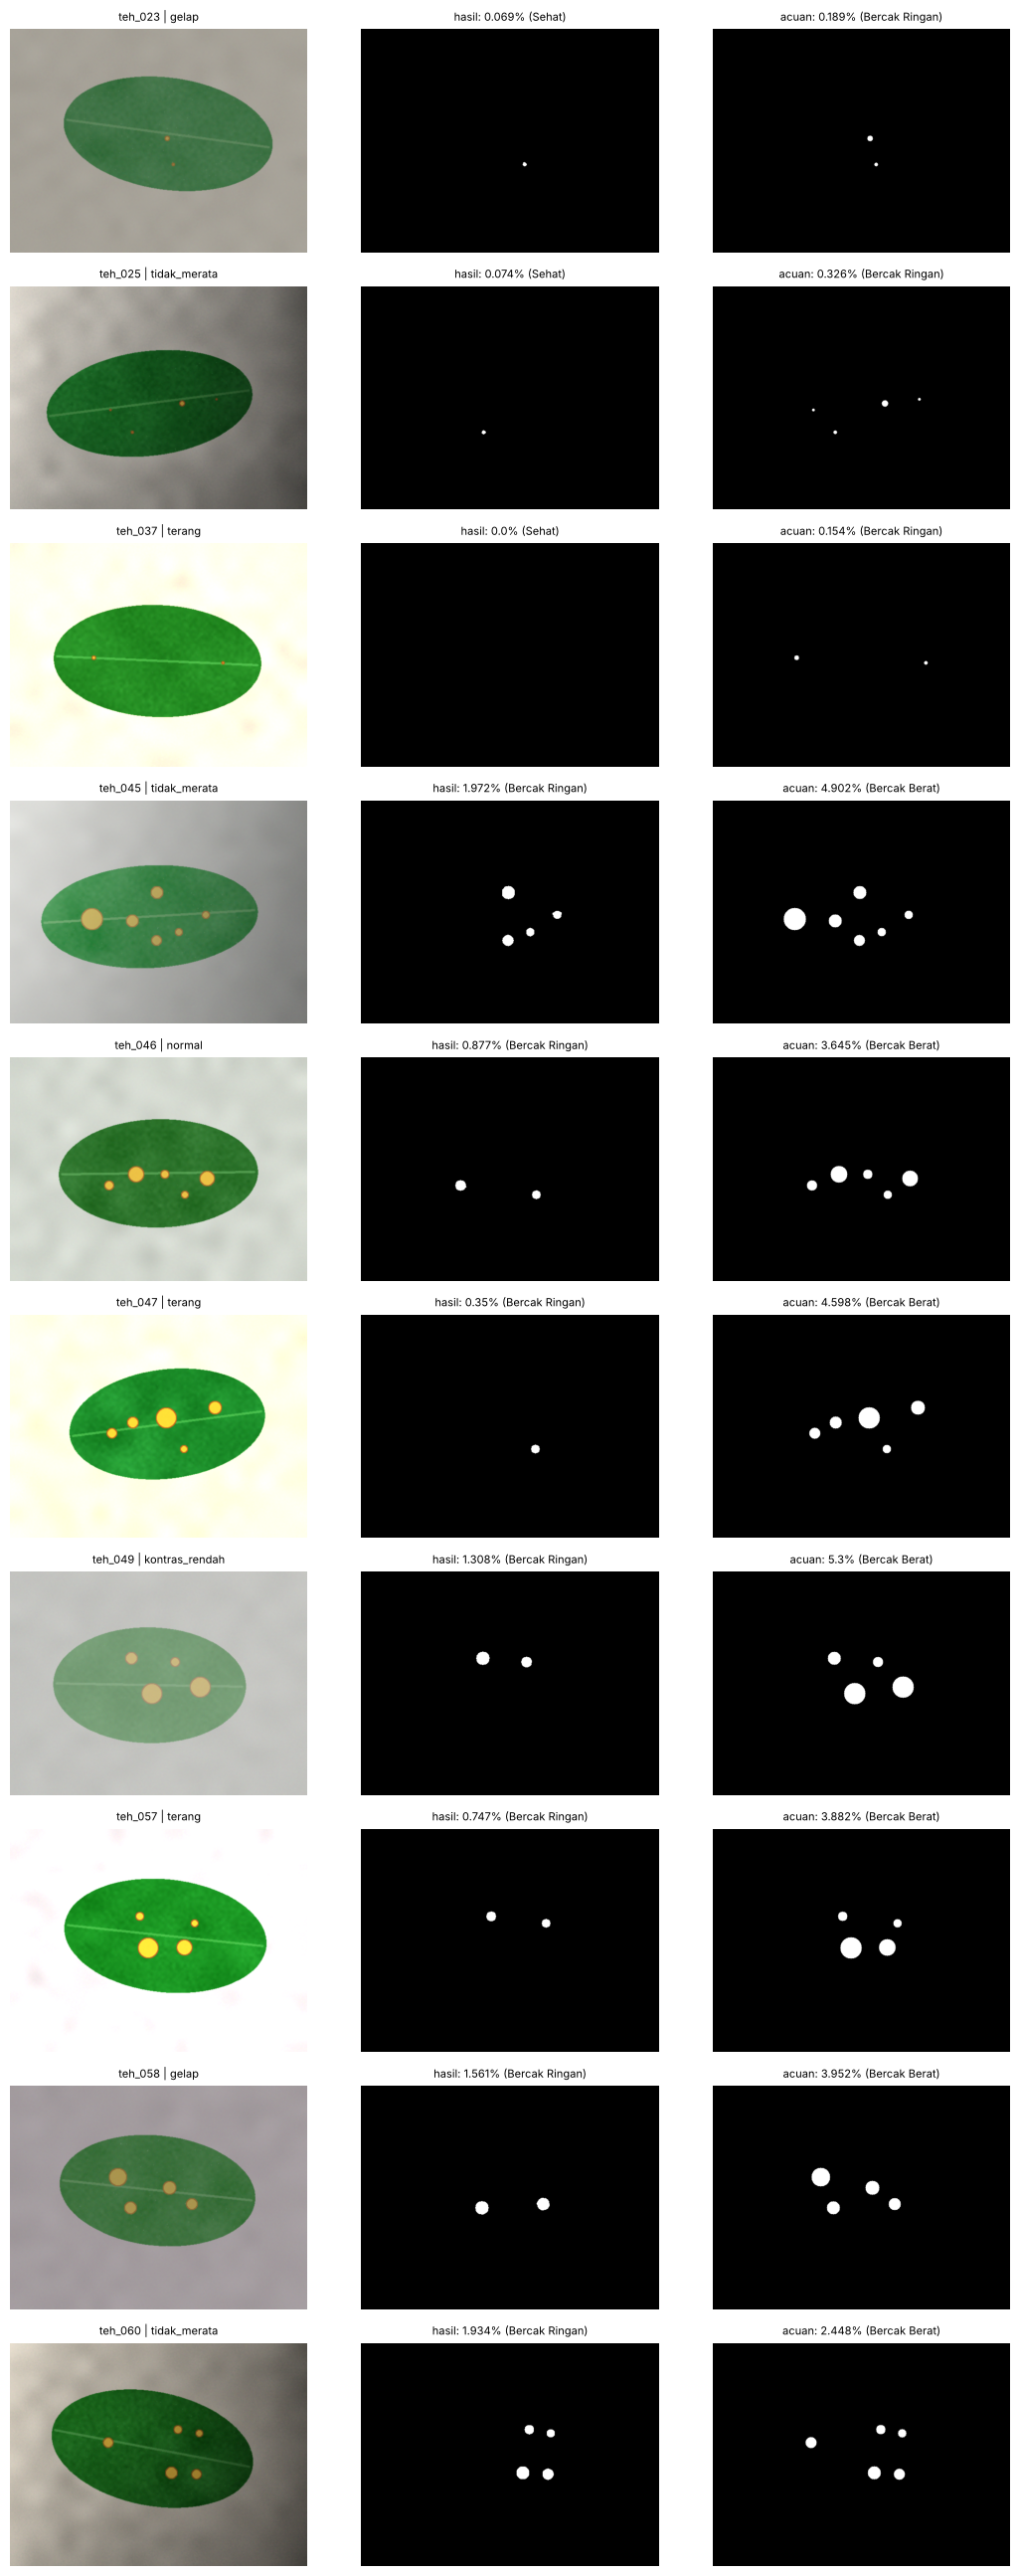

In [13]:
# Sel 7. Diagnosis kesalahan + panel citra salah kelas
def diagnosis(nama):
    pra_, md_, mb_ = CACHE[nama]; h = HASIL[nama]
    n_ac, lb_ac, st_ac, _ = cv2.connectedComponentsWithStats((mb_ > 0).astype(np.uint8), connectivity=8)
    terdeteksi, tertutup = 0, 0
    for i in range(1, n_ac):
        k = lb_ac == i
        tutup = ((h["mask_bercak"] > 0) & k).sum() / k.sum()
        terdeteksi += int(tutup > 0.2); tertutup += ((h["mask_bercak"] > 0) & k).sum()
    n_h, lb_h, _, _ = cv2.connectedComponentsWithStats((h["mask_bercak"] > 0).astype(np.uint8), connectivity=8)
    palsu = sum(1 for i in range(1, n_h) if not ((lb_h == i) & (mb_ > 0)).any())
    return {"nama": nama, "bercak_acuan": n_ac - 1, "terdeteksi": terdeteksi, "komponen_palsu": palsu,
            "piksel_acuan_tertutup_%": round(100 * tertutup / max(1, (mb_ > 0).sum()), 1),
            "IoU_daun": round(iou(h["mask_daun"], md_), 3)}

salah = ev[~ev.benar]
tab_salah = salah[["nama", "kondisi", "kelas_acuan", "kelas_prediksi", "persen_acuan", "persen_prediksi"]].merge(
    pd.DataFrame([diagnosis(n) for n in salah.nama]), on="nama")
tab_salah.to_csv("../hasil/p5_citra_salah.csv", index=False)
print("Jumlah citra salah kelas:", len(salah))
print(tab_salah.to_string(index=False))
ims, jd = [], []
for n in salah.nama:
    pra_, md_, mb_ = CACHE[n]
    ims += [pra_, HASIL[n]["mask_bercak"], mb_]
    r = ev[ev.nama == n].iloc[0]
    jd += [f"{n[:7]} | {r.kondisi}", f"hasil: {r.persen_prediksi}% ({r.kelas_prediksi})", f"acuan: {r.persen_acuan}% ({r.kelas_acuan})"]
tampil(ims, jd, baris=len(salah), ukuran=(11, 2.6 * len(salah)))
plt.savefig("../hasil/p5_citra_salah.png", dpi=100, bbox_inches="tight"); plt.show()

## Bukti untuk P5.1 dan P5.3: di tahap mana bercak hilang atau muncul?
Sel berikut mengukur recall piksel bercak acuan dan jumlah piksel palsu pada empat tahap: (1) citra biner awal, (2) sesudah opening+closing, (3) sesudah penyaringan. Tahap mask daun juga diukur dengan IoU.

In [14]:
# Sel 8. Analisis per tahap dan per kondisi cahaya
def per_tahap(nama, p=None):
    p = {**bercak.PARAM_BERCAK, **(p or {})}
    pra_, md_, mb_ = CACHE[nama]
    m_daun = mask_daun_awal(pra_)
    b0 = bercak_awal(pra_, m_daun, kanal=p["kanal"], k=p["k"])
    b1 = bercak.bersihkan(b0, p)
    b2, _ = bercak.ukur_dan_saring(b1, p)
    ac = mb_ > 0
    f = lambda m: ((m > 0) & ac).sum() / max(1, ac.sum())
    palsu = lambda m: int(((m > 0) & ~cv2.dilate(mb_, np.ones((5, 5), np.uint8)).astype(bool)).sum())
    return {"IoU_daun": iou(m_daun, md_), "recall_biner": f(b0), "recall_bersih": f(b1), "recall_saring": f(b2),
            "palsu_biner_px": palsu(b0), "palsu_bersih_px": palsu(b1), "palsu_saring_px": palsu(b2)}

tahap = pd.DataFrame([{**per_tahap(r.nama_file), "kelas": r.kelas, "kondisi": r.kondisi_cahaya} for _, r in label.iterrows()])
print("== Citra berbercak (ringan + berat): rerata recall piksel bercak acuan per tahap, per kondisi ==")
print(tahap[tahap.kelas != "sehat"].groupby("kondisi")[["IoU_daun", "recall_biner", "recall_bersih", "recall_saring"]].mean().round(3))
print()
print("== Per kelas ==")
print(tahap[tahap.kelas != "sehat"].groupby("kelas")[["recall_biner", "recall_bersih", "recall_saring"]].mean().round(3))
print()
print("== Daun sehat: rerata piksel palsu per tahap, per kondisi ==")
print(tahap[tahap.kelas == "sehat"].groupby("kondisi")[["palsu_biner_px", "palsu_bersih_px", "palsu_saring_px"]].mean().round(1))
print()
# Efek cincin cokelat: seberapa besar piksel acuan yang berada di pinggir bercak (cincin 2 piksel)?
rasio_cincin = []
for _, r in label[label.kelas != "sehat"].iterrows():
    mb_ = CACHE[r.nama_file][2]; inti = cv2.erode(mb_, np.ones((3, 3), np.uint8), iterations=2)
    rasio_cincin.append(100 * ((mb_ > 0) & (inti == 0)).sum() / (mb_ > 0).sum())
print("Porsi cincin tepi terhadap luas bercak acuan (rerata, %):", round(float(np.mean(rasio_cincin)), 1))

== Citra berbercak (ringan + berat): rerata recall piksel bercak acuan per tahap, per kondisi ==
                IoU_daun  recall_biner  recall_bersih  recall_saring
kondisi                                                             
gelap              0.998         1.000          1.000          0.633
kontras_rendah     1.000         1.000          0.999          0.537
normal             0.999         1.000          1.000          0.623
terang             1.000         1.000          1.000          0.532
tidak_merata       0.999         0.981          0.967          0.765

== Per kelas ==
        recall_biner  recall_bersih  recall_saring
kelas                                             
berat          0.999          0.999          0.564
ringan         0.993          0.988          0.671

== Daun sehat: rerata piksel palsu per tahap, per kondisi ==
                palsu_biner_px  palsu_bersih_px  palsu_saring_px
kondisi                                                         
gelap  

Status bercak acuan sesudah penyaringan (satu baris = satu bercak asli):
status  kebulatan+rasio aspek  lolos  luas
kelas                                     
berat                      39     68     0
ringan                     18     44     2

Bercak asli yang gugur: 59 dari 171 (34.5%)
Komponen penyebab gugur: median luas 3320 px, median kebulatan 0.05, median rasio aspek 11.1
(Bandingkan: bercak bulat tunggal punya kebulatan sekitar 0.9 dan rasio aspek sekitar 1.0)

Gugur karena bentuk (kebulatan/rasio aspek): 57 bercak; karena luas < luas_min: 2 bercak
Komponen gabungan yang dibuang: 30 (berisi 1 bercak: 12; berisi 2 bercak atau lebih: 18)
Persen bercak asli yang gugur, per kondisi cahaya:
kondisi
gelap             35.1
kontras_rendah    40.6
normal            42.4
terang            38.7
tidak_merata      18.4
Name: g, dtype: float64


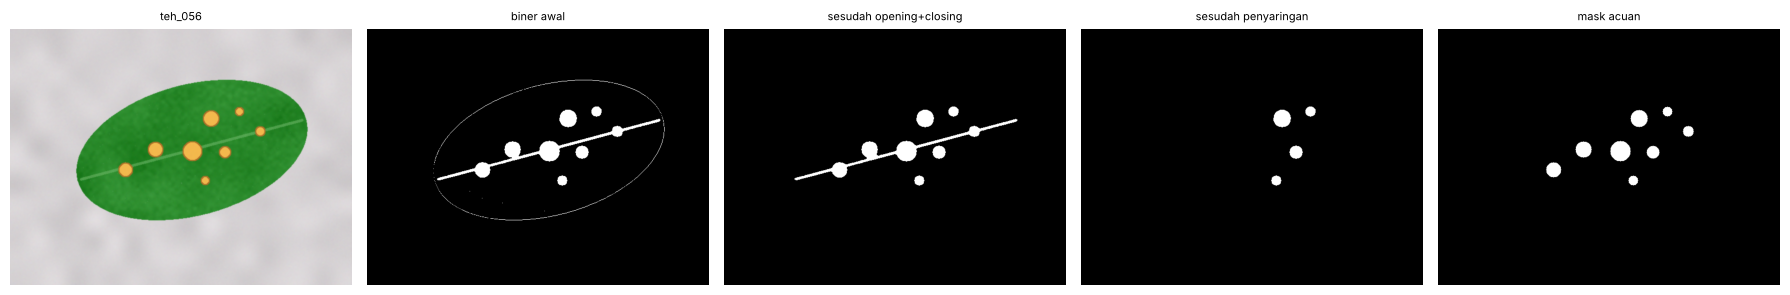

In [15]:
# Sel 8b. Mengapa bercak asli gugur? Telusuri komponen yang memuat tiap bercak acuan setelah opening+closing
p_ = bercak.PARAM_BERCAK
rows = []
for _, d in label[label.kelas != "sehat"].iterrows():
    pra_, md_, mb_ = CACHE[d.nama_file]
    b1 = bercak.bersihkan(bercak_awal(pra_, mask_daun_awal(pra_)), p_)
    n, lbl, st, _ = cv2.connectedComponentsWithStats((b1 > 0).astype(np.uint8), connectivity=8)
    na, la, sa, _ = cv2.connectedComponentsWithStats((mb_ > 0).astype(np.uint8), connectivity=8)
    for i in range(1, na):
        ids = np.unique(lbl[la == i]); ids = ids[ids > 0]
        if len(ids) == 0:
            rows.append([d.nama_file, d.kelas, d.kondisi_cahaya, "hilang (tidak ada komponen)", 0, 0.0, 0.0]); continue
        j = ids[np.argmax([(lbl[la == i] == q).sum() for q in ids])]
        kon, _ = cv2.findContours((lbl == j).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
        A = int(st[j, cv2.CC_STAT_AREA]); per = cv2.arcLength(kon[0], True)
        kb = 0.0 if per == 0 else 4 * np.pi * A / per ** 2
        w, h = cv2.minAreaRect(kon[0])[1]; ra = max(w, h) / max(min(w, h), 1)
        gagal = [x for x, c in [("luas", A < p_["luas_min"]), ("kebulatan", kb < p_["bulat_min"]), ("rasio aspek", ra > p_["rasio_maks"])] if c]
        rows.append([d.nama_file, d.kelas, d.kondisi_cahaya, "+".join(gagal) if gagal else "lolos", A, round(kb, 2), round(ra, 2)])
gugur = pd.DataFrame(rows, columns=["nama", "kelas", "kondisi", "status", "luas_komponen_px", "kebulatan", "rasio_aspek"])
gugur.to_csv("../hasil/p5_penyebab_gugur.csv", index=False)
print("Status bercak acuan sesudah penyaringan (satu baris = satu bercak asli):")
print(gugur.groupby(["kelas", "status"]).size().unstack(fill_value=0))
dua = gugur[gugur.status != "lolos"]
print("\nBercak asli yang gugur: %d dari %d (%.1f%%)" % (len(dua), len(gugur), 100 * len(dua) / len(gugur)))
print("Komponen penyebab gugur: median luas %d px, median kebulatan %.2f, median rasio aspek %.1f" %
      (dua.luas_komponen_px.median(), dua.kebulatan.median(), dua.rasio_aspek.median()))
print("(Bandingkan: bercak bulat tunggal punya kebulatan sekitar 0.9 dan rasio aspek sekitar 1.0)")
print("\nGugur karena bentuk (kebulatan/rasio aspek): %d bercak; karena luas < luas_min: %d bercak" % (dua.status.str.contains("kebulatan").sum(), (dua.status == "luas").sum()))
u_ = dua[dua.status.str.contains("kebulatan")].groupby(["nama", "luas_komponen_px"]).size()
print("Komponen gabungan yang dibuang: %d (berisi 1 bercak: %d; berisi 2 bercak atau lebih: %d)" % (len(u_), (u_ == 1).sum(), (u_ >= 2).sum()))
print("Persen bercak asli yang gugur, per kondisi cahaya:"); print((100 * gugur.assign(g=gugur.status != "lolos").groupby("kondisi").g.mean()).round(1))
# contoh visual: bercak menempel pada sisa tulang daun
cth = dua.groupby("nama").size().sort_values(ascending=False).index[0]
pra_, md_, mb_ = CACHE[cth]
b0 = bercak_awal(pra_, mask_daun_awal(pra_)); b1 = bercak.bersihkan(b0, p_)
tampil([pra_, b0, b1, HASIL[cth]["mask_bercak"], mb_], [f"{cth[:7]}", "biner awal", "sesudah opening+closing", "sesudah penyaringan", "mask acuan"], ukuran=(18, 3.4))
plt.savefig("../hasil/p5_bercak_menempel_tulang.png", dpi=100, bbox_inches="tight"); plt.show()

In [16]:
# Sel 8c. Bercak acuan yang sudah hilang atau menyusut SEBELUM penyaringan (tahap biner awal dan pembersihan)
p_ = bercak.PARAM_BERCAK
rows = []
for _, d in label[label.kelas != "sehat"].iterrows():
    pra_, md_, mb_ = CACHE[d.nama_file]
    b0_ = bercak_awal(pra_, mask_daun_awal(pra_), k=p_["k"]); b1_ = bercak.bersihkan(b0_, p_)
    na_, la_, sa_, ca_ = cv2.connectedComponentsWithStats((mb_ > 0).astype(np.uint8), connectivity=8)
    for i in range(1, na_):
        kk = la_ == i
        rows.append([d.nama_file, d.kelas, d.kondisi_cahaya, int(sa_[i, cv2.CC_STAT_AREA]), int(ca_[i][0]),
                     round(float(((b0_ > 0) & kk).sum() / kk.sum()), 2), round(float(((b1_ > 0) & kk).sum() / kk.sum()), 2)])
hil = pd.DataFrame(rows, columns=["nama", "kelas", "kondisi", "luas_acuan_px", "cx", "recall_biner", "recall_bersih"])
print("Bercak acuan yang hanya sebagian tertangkap pada citra biner awal (recall < 0.9):")
print(hil[hil.recall_biner < 0.9].to_string(index=False))
rg_ = hil[hil.kelas == "ringan"]
print("\nBercak acuan kelas ringan berukuran <= 40 piksel: %d dari %d (median %d px, minimum %d px)" % ((rg_.luas_acuan_px <= 40).sum(), len(rg_), rg_.luas_acuan_px.median(), rg_.luas_acuan_px.min()))
print("Luas daun rerata: %d px; 0.05%% = %.0f px; 0.1%% = %.0f px" % (np.mean([(CACHE[n][1] > 0).sum() for n in CACHE]), 0.0005 * np.mean([(CACHE[n][1] > 0).sum() for n in CACHE]), 0.001 * np.mean([(CACHE[n][1] > 0).sum() for n in CACHE])))


Bercak acuan yang hanya sebagian tertangkap pada citra biner awal (recall < 0.9):
       nama  kelas      kondisi  luas_acuan_px  cx  recall_biner  recall_bersih
teh_025.png ringan tidak_merata             29 444          0.72           0.59
teh_030.png ringan tidak_merata             29 344          0.72           0.59

Bercak acuan kelas ringan berukuran <= 40 piksel: 13 dari 64 (median 81 px, minimum 29 px)
Luas daun rerata: 79205 px; 0.05% = 40 px; 0.1% = 79 px


## Bukti untuk P5.2: mengapa akurasi terlalu optimistis jika batas kelas ditentukan dari seluruh dataset?

Rentang persen_bercak ACUAN (label.csv) per kelas:
          min    max
kelas               
berat   2.448  5.749
ringan  0.154  0.797
sehat   0.000  0.000

(1) Batas bawaan 0.1 / 2.0 diterapkan pada persen ACUAN (label): akurasi = 1.0
(2) Batas bawaan 0.1 / 2.0 diterapkan pada persen PREDIKSI (seluruh 60 citra): akurasi = 0.833
(3) Batas dicari pada SELURUH 60 citra: 0.05 / 1.2  -> akurasi = 0.933  (diuji pada data yang sama)
(4) 100 kali pembagian 50% latih / 50% uji (batas dicari di data latih saja):
    akurasi latih = 0.930 +- 0.031   akurasi uji = 0.916 +- 0.039
    selisih optimisme (latih - uji) = 0.014;  uji terburuk = 0.833
    batas ringan bervariasi 0.04-0.10; batas berat bervariasi 1.2-1.6


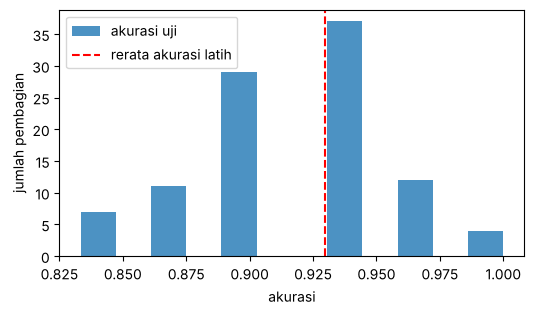

In [17]:
# Sel 9. Batas kelas dari seluruh data vs dari data latih lalu diuji pada data uji
print("Rentang persen_bercak ACUAN (label.csv) per kelas:")
print(label.groupby("kelas").persen_bercak.agg(["min", "max"]).round(3))
kls_ac = ev.kelas.values
def kelaskan(persen, br, bb): return np.where(persen >= bb, "berat", np.where(persen >= br, "ringan", "sehat"))
def akurasi(persen, kls, br, bb): return float((kelaskan(persen, br, bb) == kls).mean())
GRID_R, GRID_B = np.arange(0.02, 0.62, 0.02), np.arange(1.0, 3.5, 0.1)
def cari_batas(persen, kls):
    skor = np.array([[akurasi(persen, kls, a, b) for b in GRID_B] for a in GRID_R])
    ia, ib = np.where(skor == skor.max())
    return float(np.median(GRID_R[ia])), float(np.median(GRID_B[ib])), float(skor.max())

print("\n(1) Batas bawaan 0.1 / 2.0 diterapkan pada persen ACUAN (label): akurasi =", akurasi(ev.persen_acuan.values, kls_ac, 0.1, 2.0))
print("(2) Batas bawaan 0.1 / 2.0 diterapkan pada persen PREDIKSI (seluruh 60 citra): akurasi =", round(akurasi(ev.persen_prediksi.values, kls_ac, 0.1, 2.0), 3))
br_all, bb_all, a_all = cari_batas(ev.persen_prediksi.values, kls_ac)
print(f"(3) Batas dicari pada SELURUH 60 citra: {br_all:.2f} / {bb_all:.1f}  -> akurasi = {a_all:.3f}  (diuji pada data yang sama)")

from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=100, test_size=0.5, random_state=0)
tr, te, bs = [], [], []
for i_tr, i_te in sss.split(ev, kls_ac):
    br, bb, a_tr = cari_batas(ev.persen_prediksi.values[i_tr], kls_ac[i_tr])
    tr.append(a_tr); te.append(akurasi(ev.persen_prediksi.values[i_te], kls_ac[i_te], br, bb)); bs.append((br, bb))
bs = np.array(bs)
print(f"(4) 100 kali pembagian 50% latih / 50% uji (batas dicari di data latih saja):")
print(f"    akurasi latih = {np.mean(tr):.3f} +- {np.std(tr):.3f}   akurasi uji = {np.mean(te):.3f} +- {np.std(te):.3f}")
print(f"    selisih optimisme (latih - uji) = {np.mean(tr) - np.mean(te):.3f};  uji terburuk = {np.min(te):.3f}")
print(f"    batas ringan bervariasi {bs[:,0].min():.2f}-{bs[:,0].max():.2f}; batas berat bervariasi {bs[:,1].min():.1f}-{bs[:,1].max():.1f}")
plt.figure(figsize=(6, 3.2)); plt.hist(te, bins=12, alpha=.8, label="akurasi uji"); plt.axvline(np.mean(tr), c="r", ls="--", label="rerata akurasi latih")
plt.xlabel("akurasi"); plt.ylabel("jumlah pembagian"); plt.legend(); plt.savefig("../hasil/p5_split.png", dpi=110, bbox_inches="tight"); plt.show()

## Bukti untuk P5.4: kesalahan mana yang lebih merugikan dan parameter apa yang diubah?

In [18]:
# Sel 10. Trade-off parameter: kurangi daun berbercak yang dinilai sehat (negatif palsu) vs daun sehat dinilai berbercak (positif palsu)
def evaluasi_param(pb):
    out = []
    for _, d in label.iterrows():
        h = bercak.analisis_daun(CACHE[d.nama_file][0], pb)
        out.append((d.kelas, h["kelas"], h["persen_bercak"], d.persen_bercak))
    t = pd.DataFrame(out, columns=["kelas", "pred", "pp", "pa"])
    return {"akurasi": round(float(((t.kelas.map({"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"})) == t.pred).mean()), 3),
            "sehat_dinilai_berbercak": int(((t.kelas == "sehat") & (t.pred != "Sehat")).sum()),
            "berbercak_dinilai_sehat": int(((t.kelas != "sehat") & (t.pred == "Sehat")).sum()),
            "berat_dinilai_ringan": int(((t.kelas == "berat") & (t.pred == "Bercak Ringan")).sum()),
            "galat_persen": round(float((t.pp - t.pa).abs().mean()), 3)}
konfig = [("bawaan (k=4, luas_min=20, batas_ringan=0.1)", {}),
          ("k=3 (lebih peka)", {"k": 3.0}), ("k=6 (kurang peka)", {"k": 6.0}),
          ("luas_min=10", {"luas_min": 10}), ("luas_min=40", {"luas_min": 40}),
          ("batas_ringan=0.05", {"batas_ringan": 0.05}), ("batas_ringan=0.2", {"batas_ringan": 0.2}),
          ("k=3 + luas_min=10", {"k": 3.0, "luas_min": 10}),
          ("k=3 + opening 3 + closing 5", {"k": 3.0, "se_open": 3}),
          ("opening 3 (SE kecil)", {"se_open": 3}),
          ("batas_berat=1.5", {"batas_berat": 1.5}),
          ("batas_ringan=0.05 + batas_berat=1.5", {"batas_ringan": 0.05, "batas_berat": 1.5})]
tab_param = pd.DataFrame([{"konfigurasi": n, **evaluasi_param(p)} for n, p in konfig])
tab_param.to_csv("../hasil/p5_trade_off_parameter.csv", index=False)
tab_param

,konfigurasi,akurasi,sehat_dinilai_berbercak,berbercak_dinilai_sehat,berat_dinilai_ringan,galat_persen
0,"bawaan (k=4, luas_min=20, batas_ringan=0.1)",0.833,0,3,7,0.658
1,k=3 (lebih peka),0.850,1,2,6,0.651
2,k=6 (kurang peka),0.917,2,1,2,0.304
3,luas_min=10,0.833,0,3,7,0.657
4,luas_min=40,0.833,0,3,7,0.657
5,batas_ringan=0.05,0.867,0,1,7,0.658
6,batas_ringan=0.2,0.767,0,7,7,0.658
7,k=3 + luas_min=10,0.850,1,2,6,0.651
8,k=3 + opening 3 + closing 5,0.833,1,2,7,0.698
9,opening 3 (SE kecil),0.850,0,2,7,0.656


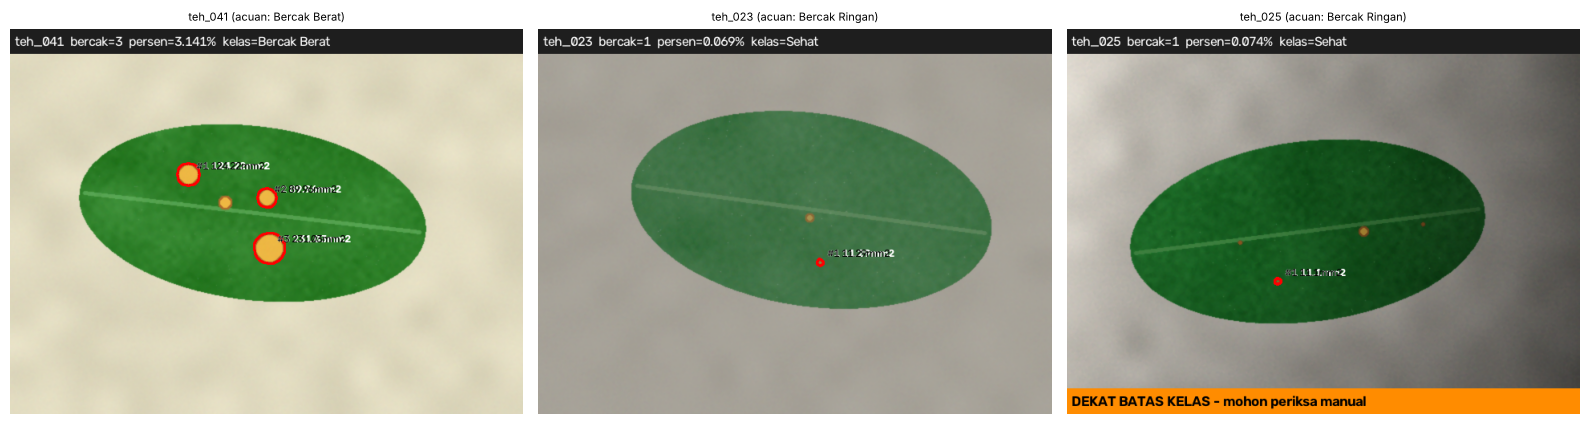

In [19]:
# Sel 11. Contoh penyajian hasil ke petugas (transparansi): kontur bercak, luas mm2, persen, kelas, dan penanda "perlu diperiksa"
def kartu_hasil(nama, p=None):
    p = {**bercak.PARAM_BERCAK, **(p or {})}
    pra_, md_, mb_ = CACHE[nama]; h = bercak.analisis_daun(pra_, p)
    out = pra_.copy()
    cv2.drawContours(out, cv2.findContours(h["mask_bercak"], cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0], -1, (0, 0, 255), 2)
    for i, b in enumerate(h["bercak"], 1):
        cv2.putText(out, f"#{i} {b['luas_mm2']}mm2", (b["cx"] + 10, b["cy"] - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 2)
        cv2.putText(out, f"#{i} {b['luas_mm2']}mm2", (b["cx"] + 10, b["cy"] - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (0, 0, 0), 1)
    pr = h["persen_bercak"]
    dekat = min(abs(pr - p["batas_ringan"]) / p["batas_ringan"], abs(pr - p["batas_berat"]) / p["batas_berat"]) < 0.3
    cv2.rectangle(out, (0, 0), (out.shape[1], 30), (30, 30, 30), -1)
    cv2.putText(out, f"{nama[:7]}  bercak={h['jumlah_bercak']}  persen={pr}%  kelas={h['kelas']}", (6, 21), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1)
    if dekat:
        cv2.rectangle(out, (0, out.shape[0] - 32), (out.shape[1], out.shape[0]), (0, 140, 255), -1)
        cv2.putText(out, "DEKAT BATAS KELAS - mohon periksa manual", (6, out.shape[0] - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)
    return out
pilih = [ev[ev.benar & (ev.kelas == "berat")].nama.iloc[0]] + list(salah.nama[:2])
tampil([kartu_hasil(n) for n in pilih], [f"{n[:7]} (acuan: {ev[ev.nama == n].kelas_acuan.iloc[0]})" for n in pilih], ukuran=(16, 4.4))
plt.savefig("../hasil/p5_kartu_hasil.png", dpi=100, bbox_inches="tight"); plt.show()

In [20]:
# Sel 11d. Seberapa efektif penanda "dekat batas kelas" (dalam 30% dari batas) menangkap citra yang salah kelas?
pbc = bercak.PARAM_BERCAK
def dekat_batas(pr):
    return min(abs(pr - pbc["batas_ringan"]) / pbc["batas_ringan"], abs(pr - pbc["batas_berat"]) / pbc["batas_berat"]) < 0.3
ev["dekat"] = ev.persen_prediksi.apply(dekat_batas)
print("Citra salah kelas yang ditandai :", int(ev[~ev.benar].dekat.sum()), "dari", int((~ev.benar).sum()))
print("Citra benar yang ikut ditandai  :", int(ev[ev.benar].dekat.sum()), "dari", int(ev.benar.sum()))
print(ev[~ev.benar][["nama", "kondisi", "kelas_acuan", "persen_prediksi", "dekat"]].to_string(index=False))


Citra salah kelas yang ditandai : 4 dari 10
Citra benar yang ikut ditandai  : 4 dari 50
       nama        kondisi   kelas_acuan  persen_prediksi  dekat
teh_023.png          gelap Bercak Ringan            0.069  False
teh_025.png   tidak_merata Bercak Ringan            0.074   True
teh_037.png         terang Bercak Ringan            0.000  False
teh_045.png   tidak_merata  Bercak Berat            1.972   True
teh_046.png         normal  Bercak Berat            0.877  False
teh_047.png         terang  Bercak Berat            0.350  False
teh_049.png kontras_rendah  Bercak Berat            1.308  False
teh_057.png         terang  Bercak Berat            0.747  False
teh_058.png          gelap  Bercak Berat            1.561   True
teh_060.png   tidak_merata  Bercak Berat            1.934   True


       nama        kondisi  komponen_palsu  luas_median_px  kebulatan_median  rasio_median
teh_001.png         normal               2              27              1.08          1.50
teh_008.png          gelap               2              22              1.13          1.25
teh_009.png kontras_rendah               1              22              1.13          1.25
teh_013.png          gelap               5              22              1.13          1.25
teh_018.png          gelap               4              24              1.11          1.38
       nama        kondisi  komponen_palsu  luas_median_px  kebulatan_median  rasio_median  persen_hasil  melampaui_batas_ringan
teh_001.png         normal               2              27              1.08          1.50         0.068                   False
teh_008.png          gelap               2              22              1.13          1.25         0.056                   False
teh_009.png kontras_rendah               1              22         

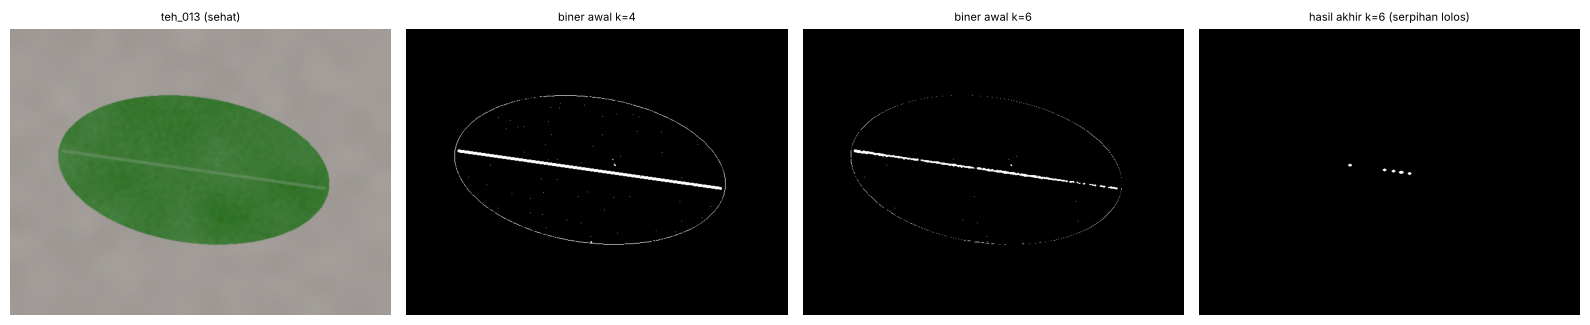

In [21]:
# Sel 11b. Mengapa k=6 (kurang peka) justru menambah daun sehat yang dinilai berbercak?
p6 = {**bercak.PARAM_BERCAK, "k": 6.0}
rows = []
for _, d in label[label.kelas == "sehat"].iterrows():
    pra_, md_, mb_ = CACHE[d.nama_file]; m_daun = mask_daun_awal(pra_)
    _, dl = bercak.ukur_dan_saring(bercak.bersihkan(bercak_awal(pra_, m_daun, k=6.0), p6), p6)
    if dl: rows.append([d.nama_file, d.kondisi_cahaya, len(dl), int(np.median([b["luas_px"] for b in dl])), round(float(np.median([b["kebulatan"] for b in dl])), 2),
                        round(float(np.median([b["rasio_aspek"] for b in dl])), 2)])
fp6 = pd.DataFrame(rows, columns=["nama", "kondisi", "komponen_palsu", "luas_median_px", "kebulatan_median", "rasio_median"])
print(fp6.to_string(index=False))
fp6["persen_hasil"] = [bercak.analisis_daun(CACHE[n][0], {"k": 6.0})["persen_bercak"] for n in fp6.nama]
print(fp6.assign(melampaui_batas_ringan=fp6.persen_hasil >= 0.1).to_string(index=False))
print("Daun sehat yang memuat serpihan lolos pada k=6: %d; yang melampaui batas_ringan 0.1%%: %d" % (len(fp6), (fp6.persen_hasil >= 0.1).sum()))
print("Serpihan bulat (kebulatan median > 0.9 dan rasio aspek median < 1.8) pada semua daun tersebut:", bool(((fp6.kebulatan_median > 0.9) & (fp6.rasio_median < 1.8)).all()))
cth6 = fp6.sort_values("komponen_palsu").nama.iloc[-1]
pra_, md_, mb_ = CACHE[cth6]; m_daun = mask_daun_awal(pra_)
b6 = bercak.bersihkan(bercak_awal(pra_, m_daun, k=6.0), p6)
tampil([pra_, bercak_awal(pra_, m_daun, k=4.0), bercak_awal(pra_, m_daun, k=6.0), bercak.ukur_dan_saring(b6, p6)[0]],
       [f"{cth6[:7]} (sehat)", "biner awal k=4", "biner awal k=6", "hasil akhir k=6 (serpihan lolos)"], ukuran=(16, 3.4))
plt.savefig("../hasil/p5_k6_serpihan.png", dpi=100, bbox_inches="tight"); plt.show()


## Usulan perbaikan untuk P5.3 (untuk diuji pada P7)
Temuan Sel 8b: penyebab utama kesalahan adalah bercak yang **menempel pada sisa tulang daun**. Ide awal: pisahkan bercak dari tulang daun memakai informasi warna, bukan hanya kecerahan kanal R. Pada citra ini bercak berwarna kuning-oranye (R lebih besar dari G), sedangkan tulang daun hijau muda (G lebih besar dari R). **Peringatan:** ini hanya uji pendahuluan pada data sintetis yang warna bercaknya memang berbeda dari tulang daun, dan nilai k dipilih pada data yang sama, sehingga hasilnya optimistis. Kebenarannya harus diuji pada P7 dengan foto nyata dan data uji terpisah.

In [22]:
# Sel 11c. Usulan: ambang median + k x MAD pada selisih kanal (R - G) alih-alih kanal R
def biner_rg(pra_, m_daun, k=4.0):
    c = pra_[:, :, 2].astype(np.float32) - pra_[:, :, 1].astype(np.float32)
    m = m_daun > 0
    med = np.median(c[m]); mad = max(1.4826 * np.median(np.abs(c[m] - med)), 1.0)
    return (((c > med + k * mad) & m) * 255).astype(np.uint8)
baris = []
for k in [4, 6, 8, 12]:
    benar, fp, fn, galat = 0, 0, 0, []
    for _, d in label.iterrows():
        pra_, md_, mb_ = CACHE[d.nama_file]; m_daun = mask_daun_awal(pra_)
        mk, _ = bercak.ukur_dan_saring(bercak.bersihkan(biner_rg(pra_, m_daun, k), bercak.PARAM_BERCAK), bercak.PARAM_BERCAK)
        persen = 100 * (mk > 0).sum() / (m_daun > 0).sum()
        kp = "berat" if persen >= 2.0 else "ringan" if persen >= 0.1 else "sehat"
        benar += kp == d.kelas; fp += (d.kelas == "sehat" and kp != "sehat"); fn += (d.kelas != "sehat" and kp == "sehat")
        galat.append(abs(persen - d.persen_bercak))
    baris.append([f"R-G, k={k}", round(benar / 60, 3), fp, fn, round(float(np.mean(galat)), 3)])
baris.insert(0, ["kanal R, k=4 (modul saat ini)", round(ev.benar.mean(), 3), int(((ev.kelas == "sehat") & (ev.kelas_prediksi != "Sehat")).sum()), int(((ev.kelas != "sehat") & (ev.kelas_prediksi == "Sehat")).sum()), round((ev.persen_prediksi - ev.persen_acuan).abs().mean(), 3)])
pd.DataFrame(baris, columns=["metode biner awal", "akurasi kelas", "sehat dinilai berbercak", "berbercak dinilai sehat", "galat persen"])

,metode biner awal,akurasi kelas,sehat dinilai berbercak,berbercak dinilai sehat,galat persen
0,"kanal R, k=4 (modul saat ini)",0.833,0,3,0.658
1,"R-G, k=4",0.983,0,1,0.254
2,"R-G, k=6",1.000,0,0,0.192
3,"R-G, k=8",0.983,0,0,0.158
4,"R-G, k=12",0.900,0,6,0.351


## Bukti untuk P5.5: aturan bentuk yang terlalu cocok dengan bercak bulat sintetis
Sel berikut membangkitkan dataset kedua dengan bercak **tak beraturan** (memanjang dan bergerigi), lalu menguji modul yang sama tanpa mengubah parameter.

                                                    bercak bulat (dataset 1)  bercak tak beraturan (dataset 2)
jumlah bercak acuan                                                   171.00                            169.00
kebulatan median                                                        0.93                              0.64
kebulatan minimum                                                       0.89                              0.39
rasio aspek median                                                      1.00                              1.35
rasio aspek maksimum                                                    1.00                              4.00
% bercak yang gagal aturan bulat_min=0.5 / rasi...                      0.00                             62.13

varian aturan                            A. aturan bawaan (bulat>=0.5, rasio<=1.8)  B. dilonggarkan (bulat>=0.2, rasio<=4)  C. tanpa aturan bentuk (hanya luas)
recall luas (tak beraturan)                                   

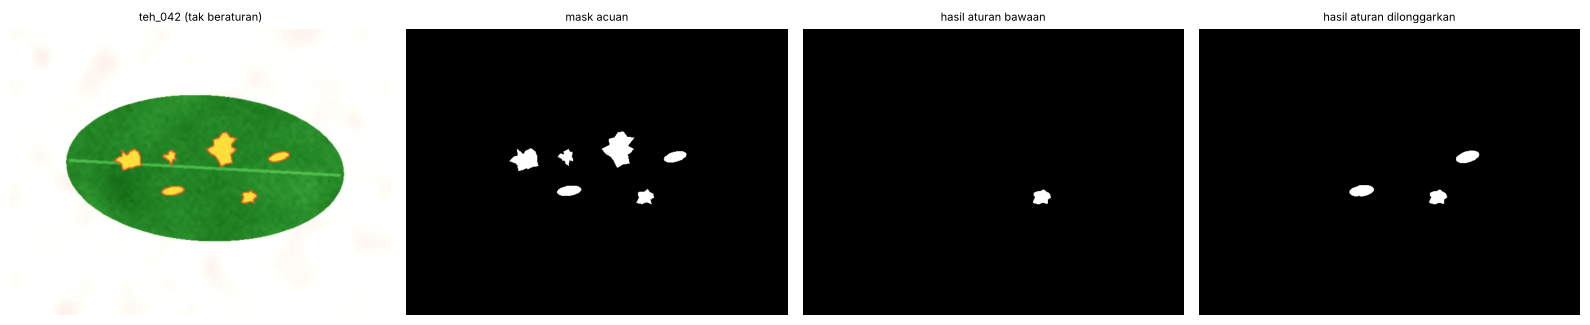

In [23]:
# Sel 12. Uji bercak tak beraturan (dataset kedua) + ukur bentuk bercak acuan
lab2 = buat_dataset(SEED + 1, "../data/sintetis_tak_beraturan", bentuk="tak_beraturan")
CACHE2 = {}
for _, d in lab2.iterrows():
    img = baca(f"../data/sintetis_tak_beraturan/citra/{d.nama_file}")
    CACHE2[d.nama_file] = (praproses(img, PARAM), cv2.imread(f"../data/sintetis_tak_beraturan/mask_daun/{d.nama_file}", 0),
                           cv2.imread(f"../data/sintetis_tak_beraturan/mask_bercak/{d.nama_file}", 0))
tanpa = {**bercak.PARAM_BERCAK, "luas_min": 0, "bulat_min": 0.0, "rasio_maks": 99}
def bentuk_acuan(cache, lab):
    rows = []
    for _, d in lab[lab.kelas != "sehat"].iterrows():
        _, daftar = bercak.ukur_dan_saring(cache[d.nama_file][2], tanpa)
        rows += [(b["kebulatan"], b["rasio_aspek"]) for b in daftar]
    return pd.DataFrame(rows, columns=["kebulatan", "rasio_aspek"])
b_bulat, b_tak = bentuk_acuan(CACHE, label), bentuk_acuan(CACHE2, lab2)
ringkas = pd.DataFrame({"bercak bulat (dataset 1)": [len(b_bulat), b_bulat.kebulatan.median(), b_bulat.kebulatan.min(), b_bulat.rasio_aspek.median(), b_bulat.rasio_aspek.max(),
                                                    100 * ((b_bulat.kebulatan < .5) | (b_bulat.rasio_aspek > 1.8)).mean()],
                        "bercak tak beraturan (dataset 2)": [len(b_tak), b_tak.kebulatan.median(), b_tak.kebulatan.min(), b_tak.rasio_aspek.median(), b_tak.rasio_aspek.max(),
                                                           100 * ((b_tak.kebulatan < .5) | (b_tak.rasio_aspek > 1.8)).mean()]},
                       index=["jumlah bercak acuan", "kebulatan median", "kebulatan minimum", "rasio aspek median", "rasio aspek maksimum",
                              "% bercak yang gagal aturan bulat_min=0.5 / rasio_maks=1.8"]).round(2)
print(ringkas); print()

def uji(cache, lab, pb):
    rows = []
    for _, d in lab.iterrows():
        pra_, md_, mb_ = cache[d.nama_file]; h = bercak.analisis_daun(pra_, pb)
        ac = mb_ > 0; rec = ((h["mask_bercak"] > 0) & ac).sum() / ac.sum() if ac.any() else np.nan
        rows.append((d.kelas, h["persen_bercak"], d.persen_bercak, h["jumlah_bercak"], jumlah_komponen(mb_), h["kelas"], rec))
    return pd.DataFrame(rows, columns=["kelas", "pp", "pa", "n_pred", "n_ac", "kelas_pred", "recall"])
ac_map = {"sehat": "Sehat", "ringan": "Bercak Ringan", "berat": "Bercak Berat"}
varian = {"A. aturan bawaan (bulat>=0.5, rasio<=1.8)": {}, "B. dilonggarkan (bulat>=0.2, rasio<=4)": {"bulat_min": 0.2, "rasio_maks": 4.0},
          "C. tanpa aturan bentuk (hanya luas)": {"bulat_min": 0.0, "rasio_maks": 99}}
baris = []
for nm, pb in varian.items():
    t2, t1 = uji(CACHE2, lab2, pb), uji(CACHE, label, pb)
    b2 = t2[t2.kelas != "sehat"]
    baris.append([nm, round(b2.recall.mean(), 3), int(b2.n_pred.sum()), int(b2.n_ac.sum()),
                  round((t2.kelas.map(ac_map) == t2.kelas_pred).mean(), 3),
                  int(((t2.kelas != "sehat") & (t2.kelas_pred == "Sehat")).sum()),
                  int(((t1.kelas == "sehat") & (t1.kelas_pred != "Sehat")).sum()),
                  round((t1.kelas.map(ac_map) == t1.kelas_pred).mean(), 3)])
tab_tak = pd.DataFrame(baris, columns=["varian aturan", "recall luas (tak beraturan)", "bercak terdeteksi", "bercak acuan",
                                       "akurasi kelas (tak beraturan)", "berbercak dinilai sehat (tak beraturan)",
                                       "sehat dinilai berbercak (dataset 1)", "akurasi kelas (dataset 1, bulat)"])
tab_tak.to_csv("../hasil/p5_uji_tak_beraturan.csv", index=False)
print(tab_tak.T.to_string(header=False))
n_pil = lab2[lab2.kelas == "berat"].nama_file.iloc[1]
pra_, md_, mb_ = CACHE2[n_pil]
tampil([pra_, mb_, bercak.analisis_daun(pra_)["mask_bercak"], bercak.analisis_daun(pra_, varian["B. dilonggarkan (bulat>=0.2, rasio<=4)"])["mask_bercak"]],
       [f"{n_pil[:7]} (tak beraturan)", "mask acuan", "hasil aturan bawaan", "hasil aturan dilonggarkan"], ukuran=(16, 3.6))
plt.savefig("../hasil/p5_tak_beraturan.png", dpi=100, bbox_inches="tight"); plt.show()

# Jawaban Pertanyaan Analisis P5.1 sampai P5.5
Seluruh angka di bawah berasal dari keluaran sel pada notebook ini (dataset sintetis, `SEED = 1007`, parameter bawaan `bercak.py` kecuali dinyatakan lain). Rujukan "Sel N" menunjuk komentar judul sel di atas. Bila `SEED` diganti, salin ulang angka dari keluaran sel Anda.

## P5.1 Seberapa tepat SIMUTEH v0.3 mengukur persen bercak dan menebak kelas?

**Ketepatan keseluruhan (Sel 5 dan Tabel 12 pada Sel 6).** Akurasi kelas 0,833 (50 dari 60 citra), galat absolut rerata persen bercak 0,658 poin persen, dan korelasi persen prediksi dengan acuan 0,854. Semua 20 daun sehat dinilai benar. Dari 20 daun ringan, 17 benar dan 3 dinilai sehat. Dari 20 daun berat, 13 benar dan 7 dinilai ringan. Tidak ada daun sehat yang dinilai berbercak.

Galatnya bersifat sistematis, bukan acak: sistem **meremehkan** persen bercak. Pada kelas berat rerata persen acuan 4,383% tetapi prediksinya 2,539% (kurang sekitar 42%); pada kelas ringan 0,395% berbanding 0,312% (kurang sekitar 21%).

**Sepuluh citra salah kelas (Sel 7, Langkah 5.3).**

| Citra | Kondisi | Acuan menjadi prediksi | Persen acuan / prediksi | Bercak acuan terdeteksi |
|---|---|---|---|---|
| teh_023 | gelap | ringan menjadi sehat | 0,189 / 0,069 | 1 dari 2 |
| teh_025 | tidak merata | ringan menjadi sehat | 0,326 / 0,074 | 1 dari 4 |
| teh_037 | terang | ringan menjadi sehat | 0,154 / 0,000 | 0 dari 2 |
| teh_045 | tidak merata | berat menjadi ringan | 4,902 / 1,972 | 4 dari 6 |
| teh_046 | normal | berat menjadi ringan | 3,645 / 0,877 | 2 dari 5 |
| teh_047 | terang | berat menjadi ringan | 4,598 / 0,350 | 1 dari 5 |
| teh_049 | kontras rendah | berat menjadi ringan | 5,300 / 1,308 | 2 dari 4 |
| teh_057 | terang | berat menjadi ringan | 3,882 / 0,747 | 2 dari 4 |
| teh_058 | gelap | berat menjadi ringan | 3,952 / 1,561 | 2 dari 4 |
| teh_060 | tidak merata | berat menjadi ringan | 2,448 / 1,934 | 4 dari 5 |

**Penyebab (Sel 8, Sel 8b, dan Sel 8c).** Pola kesepuluh kesalahan sama. Mask daun sudah tepat (IoU 0,997 sampai 1,000, Sel 7) dan citra biner awal sudah menangkap hampir seluruh piksel bercak acuan (recall 0,999 untuk berat dan 0,993 untuk ringan). Kehilangan terjadi di tahap **penyaringan**: recall turun menjadi 0,564 (berat) dan 0,671 (ringan).

Sel 8b menunjukkan 59 dari 171 bercak asli (34,5%) gugur: 57 karena gagal aturan bentuk (kebulatan dan rasio aspek) dan 2 karena luas di bawah `luas_min`. Ke-57 bercak itu berada di 30 komponen gabungan yang dibuang (12 berisi satu bercak, 18 berisi dua bercak atau lebih). Komponen gabungan itu bukan bercak tunggal: mediannya seluas 3.320 piksel dengan kebulatan 0,05 dan rasio aspek 11,1 (bercak bulat tunggal berkebulatan sekitar 0,9 dan rasio aspek 1,0). Artinya bercak yang **menempel pada sisa tulang daun** ikut tersambung menjadi satu komponen panjang. Sisa tulang daun tidak habis oleh opening SE elips 5 x 5: pada daun sehat piksel palsu hanya turun dari sekitar 2.900 sampai 3.100 menjadi sekitar 2.050 sampai 2.180 setelah pembersihan (Sel 8), lalu closing ikut menyambungkan bercak yang berdekatan. Aturan rasio aspek kemudian membuang seluruh komponen gabungan itu, **termasuk bercak aslinya** (lihat panel `p5_bercak_menempel_tulang.png`). Kesepuluh citra salah kelas semuanya memuat paling sedikit satu bercak yang terbuang dengan cara ini (rinciannya per bercak ada di `hasil/p5_penyebab_gugur.csv`); pada teh_037 kedua bercak (81 dan 49 piksel) berada dalam satu komponen 2.260 piksel sehingga persen prediksi 0,000.

Dua kesalahan lain perlu dicatat. (1) teh_025: ada bercak acuan 29 piksel di sisi kanan citra yang hanya 72% tertangkap pada citra biner awal dan menyusut menjadi 17 piksel setelah pembersihan, di bawah `luas_min` 20 (Sel 8c). (2) teh_045 dan teh_060 sebenarnya **hampir benar**: prediksinya 1,972% dan 1,934%, hanya sedikit di bawah batas berat 2,0%, jadi selisih kecil pada penyaringan sudah mengubah kelas.

## P5.2 Mengapa batas kelas 0,1% dan 2,0% dari label.csv membuat akurasi terlalu optimistis?

Batas 0,1% dan 2,0% dipilih dengan melihat `persen_bercak` **acuan** seluruh dataset. Rentangnya: ringan 0,154 sampai 0,797 dan berat 2,448 sampai 5,749, sehingga ada celah lebar (0,797 sampai 2,448) tempat batas dipasang. Hasilnya, pada persen acuan akurasi = 1,000, tetapi itu hanya membuktikan bahwa batas cocok dengan data yang dipakai untuk menentukannya (Sel 9). Ada tiga masalah:

1. **Kebocoran data (data leakage).** Data yang sama dipakai untuk menentukan batas dan menilai akurasi. Bila batas dicari lagi pada seluruh 60 citra memakai persen prediksi, hasilnya 0,05 / 1,2 dengan akurasi 0,933, lebih tinggi dari 0,833 pada batas bawaan. Kenaikan 10 poin ini bukan kemampuan sistem yang membaik, melainkan batas yang menyesuaikan diri dengan kesalahan sistematiknya (batas berat turun dari 2,0 ke 1,2, sejalan dengan persen daun berat yang diremehkan). Kesalahan segmentasinya sendiri tidak hilang, hanya tertutup oleh batas.
2. **Batas dipasang pada ukuran yang berbeda.** Batas dibaca dari persen acuan (bebas galat), tetapi dipakai pada persen prediksi yang punya galat rerata 0,658. Itu sebabnya akurasi turun dari 1,000 menjadi 0,833, yaitu 16,7 poin lebih rendah daripada angka "sempurna" tadi.
3. **Batas tidak stabil.** Pada 100 kali pembagian acak 50% latih dan 50% uji (stratified), batas yang dipilih dari data latih berubah-ubah (ringan 0,04 sampai 0,10 dan berat 1,2 sampai 1,6). Akurasi latih rerata 0,930 ± 0,031, akurasi uji rerata 0,916 ± 0,039, selisih optimisme 0,014, dan hasil uji terburuk 0,833.

**Catatan kejujuran:** selisih latih-uji pada data ini kecil (0,014) karena data sintetis bersih dan kelasnya terpisah rapi, sehingga bahaya terbesar di sini bukan overfitting batas melainkan angka 1,000 yang menutupi galat segmentasi. Pada foto nyata selisihnya wajar lebih besar. Angka uji 0,916 pun masih optimistis karena parameter lain (k, ukuran SE, `luas_min`) tidak dipisahkan dari data uji, dan tiap pembagian hanya menguji 30 citra.

**Cara yang seharusnya** (selaras dengan P11): bagi data **per kelas dan kondisi cahaya** (stratified) dengan seed tetap menjadi data **latih** (mencari batas), **validasi** (memilih parameter seperti k, SE, `luas_min`), dan **uji** (dipakai sekali di akhir untuk melaporkan akurasi). Karena data hanya 60 citra, validasi silang berulang lebih meyakinkan daripada satu pembagian. Batas kelas juga sebaiknya berpijak pada standar mutu atau penilaian ahli, bukan hanya pada celah di data.

## P5.3 Kondisi cahaya mana yang menghasilkan kesalahan, dan dari tahap mana asalnya?

**Kesalahan per kondisi (Sel 5 dan Sel 7).** Akurasi per kondisi (12 citra tiap kondisi): kontras rendah 0,92, normal 0,92, gelap 0,83, terang 0,75, dan tidak merata 0,75 (Tabel 12 mencatat kedua nilai terendah yang kembar). Jumlah citra salah: terang 3 (teh_037, 047, 057), tidak merata 3 (teh_025, 045, 060), gelap 2 (teh_023, 058), normal 1 (teh_046), dan kontras rendah 1 (teh_049), total 10. Karena tiap kondisi hanya 12 citra, selisih satu citra setara 0,08; kesalahan muncul di **semua** kondisi, jadi urutan ini jangan ditafsirkan sebagai pengaruh cahaya yang kuat.

**Asal kesalahan (Sel 8, 8b, dan 8c).**
- **Praproses bukan penyebab utama.** IoU mask daun 0,998 sampai 1,000 pada semua kondisi, dan kondisi normal pun ikut salah (1 citra).
- **Citra biner awal hampir tidak bermasalah.** Recall piksel bercak acuan 1,000 untuk gelap, kontras rendah, normal, dan terang. Hanya kondisi tidak merata sedikit turun (0,981 pada biner awal dan 0,967 sesudah pembersihan). Sel 8c menunjukkan penyebabnya hanya dua bercak terkecil (29 piksel) pada teh_025 dan teh_030, keduanya di setengah kanan citra (cx 444 dan 344), yang hanya 72% tertangkap pada biner awal dan 59% sesudah pembersihan. Kaitannya dengan sisi citra yang lebih teduh adalah dugaan yang cocok dengan polanya, belum diuji terpisah. Bercak sekecil itu tidak langka: 13 dari 64 bercak ringan berukuran 40 piksel atau kurang (median 81 piksel).
- **Penyaringan adalah sumber terbesar.** Recall jatuh ke 0,532 (terang), 0,537 (kontras rendah), 0,623 (normal), 0,633 (gelap), dan 0,765 (tidak merata). Penyebabnya bercak yang menempel pada sisa tulang daun (lihat P5.1), yang terjadi di semua kondisi: persen bercak asli yang gugur adalah 35,1% (gelap), 40,6% (kontras rendah), 42,4% (normal), 38,7% (terang), dan 18,4% (tidak merata).
- **Mengapa tidak merata paling sedikit gugur tetapi tetap salah 3 citra?** Pada daun sehat kondisi ini punya piksel palsu biner awal paling sedikit (rerata 1.143 piksel, dibanding 2.912 sampai 3.143 pada kondisi lain), sehingga lebih sedikit tulang daun yang menyambung ke bercak (dugaan: gradien cahaya melebarkan MAD sehingga ambang median + k x MAD naik; belum diuji terpisah). Tetapi tiga kesalahannya berasal dari sebab lain: bercak kecil yang menyusut di bawah `luas_min` (teh_025) dan dua citra berat yang prediksinya hanya sedikit di bawah batas 2,0% (teh_045 1,972% dan teh_060 1,934%).
- **Daun sehat.** Sisa tulang daun sekitar 2.050 sampai 2.180 piksel sesudah pembersihan (755 piksel pada tidak merata) dibuang tuntas oleh penyaringan (0 piksel rerata, kecuali rerata 5,5 piksel pada tidak merata, setara 22 piksel dalam total empat daun). Inilah mengapa aturan bentuk tetap dibutuhkan.

**Usulan perbaikan untuk diuji pada P7.**
1. Pisahkan bercak dari tulang daun sebelum penyaringan: buang sisa tulang daun lebih dulu atau pecah komponen gabungan dengan distance transform dan watershed (tantangan opsional pada petunjuk), bukan membuang seluruh komponen panjang.
2. Gunakan informasi warna. Uji pendahuluan pada Sel 11c memakai selisih kanal R dikurangi G (bercak kuning-oranye, tulang daun hijau muda): akurasi naik dari 0,833 menjadi 0,983 (k = 4), 1,000 (k = 6), dan 0,983 (k = 8), dan galat persen turun dari 0,658 menjadi 0,254, 0,192, dan 0,158. Namun k = 12 turun ke 0,900 dengan 6 daun berbercak dinilai sehat. **Peringatan:** warna bercak pada data sintetis ini memang dirancang berbeda dari tulang daun dan k dipilih pada data yang sama, jadi hasil ini optimistis dan baru berarti bila lolos uji pada foto nyata dengan data uji terpisah.
3. Untuk kondisi tidak merata, hitung ambang secara lokal (adaptif per blok) agar bercak kecil di sisi teduh tidak hilang.

## P5.4 Kesalahan mana yang lebih merugikan, parameter apa yang diubah, dan bagaimana menampilkan hasil?

**Mana yang lebih merugikan.** Keduanya merugikan dengan cara berbeda. Daun berbercak dinilai sehat berisiko meloloskan daun cacat ke pengolahan, menurunkan mutu, dan membiarkan penyakit tidak tertangani. Daun sehat dinilai berbercak merugikan petani secara langsung (daun diturunkan kelasnya, harga turun) dan, bila sering, membuat petugas tidak lagi mempercayai sistem. Karena SIMUTEH baru memberi *tebakan pertama* yang akan diperiksa petugas, saya menilai **daun berbercak dinilai sehat lebih berbahaya**, sebab kesalahan jenis ini tidak memicu pemeriksaan ulang, sedangkan alarm palsu masih bisa dikoreksi petugas. Namun keputusan akhir bergantung pada kebijakan kelompok tani dan sebaiknya disepakati bersama mereka. Pada data ini ada juga jenis ketiga yang tidak boleh dilupakan: 7 daun berat dinilai ringan (meremehkan tingkat keparahan).

**Parameter yang diubah dan konsekuensinya (Sel 10).** Kondisi awal: 0 daun sehat dinilai berbercak, 3 daun berbercak dinilai sehat (ketiganya ringan), 7 daun berat dinilai ringan, akurasi 0,833.

| Perubahan | Sehat dinilai berbercak | Berbercak dinilai sehat | Berat dinilai ringan | Akurasi | Galat persen |
|---|---|---|---|---|---|
| bawaan | 0 | 3 | 7 | 0,833 | 0,658 |
| `batas_ringan` 0,05 | 0 | 1 | 7 | 0,867 | 0,658 |
| `batas_ringan` 0,2 | 0 | 7 | 7 | 0,767 | 0,658 |
| `batas_berat` 1,5 | 0 | 3 | 4 | 0,883 | 0,658 |
| `batas_ringan` 0,05 + `batas_berat` 1,5 | 0 | 1 | 4 | 0,917 | 0,658 |
| k = 3 (lebih peka) | 1 | 2 | 6 | 0,850 | 0,651 |
| k = 6 (kurang peka) | 2 | 1 | 2 | 0,917 | 0,304 |
| `luas_min` 10 atau 40 | 0 | 3 | 7 | 0,833 | 0,657 |
| opening 3 (SE kecil) | 0 | 2 | 7 | 0,850 | 0,656 |

Untuk mengurangi daun berbercak dinilai sehat, yang saya pilih adalah menurunkan **`batas_ringan` dari 0,1 menjadi 0,05**: jumlahnya turun dari 3 menjadi 1, akurasi naik ke 0,867, dan belum menambah alarm palsu pada data ini. Perubahan ini **belum** dimasukkan ke `param_bercak.json` (Sel 5 memakai `PB = {}`) karena disetel pada data yang sama (lihat P5.2); untuk memakainya, isi `PB = {"batas_ringan": 0.05}` pada Sel 5 dan jalankan ulang. Konsekuensinya, 0,05% setara sekitar 40 piksel (luas daun rerata 79.205 piksel, Sel 8c), jadi pada foto nyata derau atau pantulan kecil lebih mudah dianggap bercak. Menaikkan kepekaan lewat k = 3 hanya sedikit membantu (daun berbercak dinilai sehat 3 menjadi 2) dan sudah menambah 1 alarm palsu. Menurunkan kepekaan lewat k = 6 memberi akurasi tertinggi di antara perubahan tunggal dan galat persen terendah (0,304), tetapi menambah 2 daun sehat dinilai berbercak: Sel 11b menunjukkan 5 daun sehat memuat serpihan tulang daun yang bulat (kebulatan median di atas 0,9 dan rasio aspek di bawah 1,8) sehingga lolos aturan bentuk, dan 2 di antaranya (teh_013 dan teh_018, 0,136% dan 0,123%) melampaui batas ringan 0,1%. `luas_min` tidak berpengaruh karena penyebab kesalahannya bukan ukuran bercak.

Untuk 7 daun berat yang dinilai ringan, menurunkan `batas_berat` ke 1,5 mengurangi jumlahnya menjadi 4, dan bersama `batas_ringan` 0,05 akurasi menjadi 0,917 tanpa alarm palsu. **Peringatan:** itu menyesuaikan batas terhadap kesalahan yang sama (lihat P5.2), bukan memperbaiki penyebabnya. Akar masalahnya tetap penyambungan dengan tulang daun (lihat P5.3), sehingga mengubah ambang hanya memindahkan kesalahan, dan besar peremehan pada foto nyata belum tentu sama.

**Penyajian agar petugas tetap dapat memeriksa (amanah dan transparansi).** Sel 11 memperlihatkan contohnya: kontur setiap bercak pada foto, nomor dan luas tiap bercak dalam mm², nilai persen bercak (bukan hanya nama kelas), serta penanda **"dekat batas kelas, mohon periksa manual"** bila persen berada dalam 30% dari batas kelas. Sel 11d menguji penanda ini: ia menangkap 4 dari 10 citra salah (teh_025, 045, 058, 060) dan ikut menandai 4 dari 50 citra yang benar. Jadi 6 kesalahan lolos tanpa penanda (teh_023, 037, 046, 047, 049, 057) karena persen prediksinya jauh dari batas; itu adalah bercak yang terbuang bersama tulang daun, yang tidak terlihat dari angka persen saja. Penanda ini membantu tetapi **tidak cukup**; SIMUTEH sebaiknya juga menyatakan bahwa hasilnya tebakan awal, menampilkan kontur komponen yang dibuang sehingga petugas dapat melihat bercak yang tidak terhitung, mencatat keterbatasan yang sudah diketahui (cenderung meremehkan bercak yang menempel tulang daun, belum diuji pada foto nyata), dan membiarkan petugas mengoreksi kelas serta menyimpan koreksinya. Cara membedakan komponen gabungan bercak-tulang dari tulang daun murni pada daun sehat belum diuji dan menjadi bahan P7.

## P5.5 Aturan mana yang terlalu cocok dengan bercak bulat sintetis, dan bagaimana mengujinya?

**Aturan yang terlalu cocok:** `bulat_min` = 0,5 dan `rasio_maks` = 1,8. Keduanya ditetapkan dari bentuk lingkaran sempurna. Opening SE elips 5 x 5 dan `luas_min` = 20 juga diam-diam mengandaikan bercak berukuran dan berbentuk "padat": bercak 29 piksel pada teh_025 menyusut menjadi 17 piksel dan gugur (Sel 8c).

**Pengujian yang sudah dilakukan (Sel 12).** Saya membangkitkan dataset kedua (SEED + 1 = 1008) dengan bercak tak beraturan (setengahnya memanjang, setengahnya bergerigi), lalu memakai modul yang sama tanpa mengubah parameter. Ini hanya simulasi, bukan foto nyata.

| Ukuran bentuk bercak acuan | Bulat (dataset 1) | Tak beraturan (dataset 2) |
|---|---|---|
| Jumlah bercak | 171 | 169 |
| Kebulatan median / minimum | 0,93 / 0,89 | 0,64 / 0,39 |
| Rasio aspek median / maksimum | 1,00 / 1,00 | 1,35 / 4,00 |
| Bercak yang gagal aturan 0,5 / 1,8 | 0% | 62,1% |

| Varian aturan | Recall luas bercak | Bercak terdeteksi | Akurasi kelas | Berbercak dinilai sehat | Sehat dinilai berbercak (dataset 1) |
|---|---|---|---|---|---|
| A. bawaan (0,5 / 1,8) | 0,378 | 74 dari 169 | 0,733 | 5 | 0 dari 20 |
| B. dilonggarkan (0,2 / 4) | 0,602 | 127 dari 169 | 0,817 | 2 | 0 dari 20 |
| C. tanpa aturan bentuk | 0,972 | 171 (acuan 169) | 0,367 | 0 | 20 dari 20 |

Aturan bawaan membuang 62,1% bercak tak beraturan karena bentuknya, dan hanya 37,8% luas bercak yang tertangkap (recall luas 0,378), padahal pada bercak bulat tidak ada satu pun yang gagal. Akurasi kelas turun lebih landai (0,833 pada dataset bulat menjadi 0,733 pada dataset tak beraturan) karena batas kelas rendah (0,1% dan 2,0%) masih terlampaui oleh sebagian bercak yang selamat; tetapi **luas dan persen bercak yang dilaporkan jauh meleset**, dan 5 daun berbercak dinilai sehat. Perbandingan akurasi ini mencampur pengaruh bentuk dengan pengaruh sampel acak yang berbeda (SEED berbeda), sehingga bukti yang lebih langsung adalah persen bercak yang gagal aturan dan recall luas. Melonggarkan aturan (varian B) memperbaiki akurasi menjadi 0,817 tanpa menambah alarm palsu pada dataset 1. Menghapus aturan bentuk sama sekali (varian C) mengembalikan hampir seluruh luas bercak, tetapi **seluruh 20 daun sehat dinilai berbercak** karena sisa tulang daun lolos (jumlah "terdeteksi" 171 melebihi 169 karena sisa tulang daun dan komponen gabungan ikut terhitung, bukan karena semua bercak cocok satu-satu). Jadi aturan bentuk memang diperlukan untuk menyingkirkan tulang daun, tetapi **bentuk bukan penanda yang cukup andal** bila bercak nyata tidak bulat.

**Cara menguji pada foto nyata.**
1. Kumpulkan foto bercak nyata yang beragam (memanjang, bergerigi, menyatu, berbeda varietas dan cahaya), beri anotasi mask acuan secara manual, dan simpan sebagai **data uji yang tidak dipakai untuk menyetel parameter**.
2. Ukur kebulatan dan rasio aspek komponen yang benar dan palsu pada data nyata (diagram sebar Langkah 4.4), lalu bandingkan dengan Sel 12: bila sebaran bercak nyata bergeser dari bulat, ambang `bulat_min` dan `rasio_maks` harus dikalibrasi ulang.
3. Laporkan recall luas, galat jumlah bercak, galat persen, dan akurasi kelas pada data uji, serta jalankan analisis sensitivitas (grid `bulat_min` dan `rasio_maks`) untuk melihat seberapa rapuh hasilnya.
4. Cari penanda yang tidak bergantung pada bentuk, misalnya warna (selisih R-G pada P5.3) atau posisi terhadap garis tulang daun, agar tulang daun dapat dibedakan tanpa mensyaratkan bercak berbentuk bulat.

## Refleksi singkat dan keterbatasan

- **Data sintetis.** Semua temuan berasal dari dataset sintetis (`SEED = 1007`) dengan bercak bulat dan tulang daun yang dirancang sederhana, dibangkitkan oleh pembangkit buatan sendiri yang belum tentu identik dengan dataset resmi. Hasilnya menunjukkan cara berpikir dan titik rawan metode, bukan kinerja pada foto lapangan.
- **Pemakaian AI generatif (isi sesuai kenyataan Anda).** Draf kerangka notebook, generator dataset, dan draf jawaban dibantu Claude (AI generatif dari Anthropic); penggantian `SEED` ke 1007, penjalanan ulang seluruh sel, dan penulisan ulang jawaban dengan angka baru juga dibantu Claude. Kode dijalankan dan angkanya diambil dari keluaran sel. Saya wajib dapat menjelaskan setiap baris kode dan setiap angka.
- **Tanggung jawab.** SIMUTEH ditempatkan sebagai alat bantu keputusan, bukan pengganti petugas: hasil disertai bukti visual, penanda ketidakpastian (yang terbukti belum cukup, lihat P5.4), dan ruang koreksi, sesuai nilai amanah dan transparansi.

In [24]:
# Sel 13. Mengemas seluruh hasil menjadi satu berkas ZIP dan (di Colab) mengunduhnya
import shutil
shutil.make_archive("/content/simuteh_P5-P6" if os.path.isdir("/content") else "../simuteh_P5-P6", "zip", "..")
print("ZIP dibuat. Isi folder hasil/:"); print(sorted(os.listdir("../hasil")))
try:
    from google.colab import files
    files.download("/content/simuteh_P5-P6.zip")
except Exception as e:
    print("(Bukan di Colab, unduhan otomatis dilewati)")

ZIP dibuat. Isi folder hasil/:
['p5_bercak_menempel_tulang.png', 'p5_citra_salah.csv', 'p5_citra_salah.png', 'p5_dataset_contoh.png', 'p5_k6_serpihan.png', 'p5_kartu_hasil.png', 'p5_penyebab_gugur.csv', 'p5_scatter_persen.png', 'p5_split.png', 'p5_tak_beraturan.png', 'p5_trade_off_parameter.csv', 'p5_uji_tak_beraturan.csv', 'p6_evaluasi_bercak.csv', 'p6_tabel12.csv', 'param_bercak.json', 'param_praproses.json']
(Bukan di Colab, unduhan otomatis dilewati)
